# **Project Name**    -  Yes Bank Stock Closing Price Prediction

##### **Project Type**    - Regression
##### **Contribution**    - Individual
##### **Team Member 1 -** Charles Patel 

# **Project Summary -**

Yes Bank has been in the news since 2018 because of the fraud case involving its co-founder Rana Kapoor. This project studies how the bank's monthly stock prices behaved over 15 years (Jul-2005 to Nov-2020, 185 months of Open, High, Low and Close) and builds a regression model that predicts the closing price of the month.

**Data and exploration.** The data is clean (no missing values or duplicates) but strongly right-skewed and trending. Seventeen charts were produced following the Univariate, Bivariate and Multivariate approach. They show that the price rose about 29x until Jul-2018 (peak Rs 367.9) and then fell about 97% by Jul-2020. Open, High, Low and Close are all correlated at 0.98 or higher, and a 12-month moving average and rolling volatility reveal that risk rises sharply in crises. Three hypothesis tests confirmed that returns after Sep-2018 were significantly lower (Mann-Whitney p = 0.003), that monthly price swings roughly doubled (p < 0.001), and that there is no significant seasonality across calendar months (Kruskal-Wallis p = 0.34).

**Pre-processing.** There was nothing to impute. Outliers (such as the 2017-18 peak and the Mar-2020 swing) are real market events, so they were kept and tamed with a log transform. To avoid the 0.99 correlation between raw prices, all features were expressed relative to the Open price (High/Open, Low/Open, last close vs Open, trend and momentum), and the target became ln(Close/Open); maximum VIF fell to 5.8. Features were chosen with F-scores, RFE and Lasso on the training data only. Data was scaled inside pipelines to prevent leakage and split chronologically (145 training months, 37 test months) rather than randomly, because a random split would leak future information.

**Modelling.** Linear Regression, Random Forest and Gradient Boosting were trained, cross-validated with time-series folds and tuned with GridSearchCV or RandomizedSearchCV (Ridge for the linear family). Results were compared on the test months in rupees, together with two naive baselines. Linear Regression gave the best result (R² 0.986, RMSE Rs 14.96, MAE Rs 9.46, MAPE 8.0%), cutting percentage error by about 64% compared with simple guesses (about 22%). Tuning gave little or no gain, which shows that the relationship is close to linear once expressed as ratios. Permutation importance showed that the month's high-above-open and low-below-open ratios explain almost everything.

**Key insights for the business.** The stock became both weaker and about twice as volatile after Sep-2018, so any monitoring of recovery should track monthly returns turning positive and the monthly price range shrinking back towards its pre-2018 level of about 17% of the Open. Calendar-month patterns should not be used for decisions. A simple, explainable model was preferred over complex ones because it was more accurate, easier to defend, and less prone to overfitting on only 182 usable months.

**Business meaning and limits.** About 73% of test months were predicted within 10%. The largest errors fall in the crash months of 2018-19, where the model over-predicts. Since the month's High and Low are only known at month-end, the model is a nowcasting and validation tool, not a trading signal. The final model was saved with joblib, reloaded and sanity-checked on unseen data.

# **GitHub Link -**

Add your GitHub repository link here after you upload this notebook and the CSV.

# **Problem Statement**

**Yes Bank has been in the news since 2018 because of the fraud case involving its co-founder Rana Kapoor. This
project uses the bank's monthly stock prices since its inception (Jul-2005 to Nov-2020: Open, High, Low, Close) to build
a regression model that predicts the stock's closing price for the month, and checks how well predictive models cope
with a period that contains a major shock.**

# **General Guidelines** : -
1. Code is structured into small reusable functions and commented.
2. Exception handling is used for data loading, and the notebook is written to run top-to-bottom in one go.
3. Every chart answers: why this chart, what insight, and what business impact (positive / negative).
4. 17 charts are produced following the UBM rule (Univariate, Bivariate, Multivariate).
5. Three ML algorithms are built, cross-validated and tuned, and each is explained with metrics and business meaning.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [3]:
# Import Libraries
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.feature_selection import RFE, f_regression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42          # fixed seed so results are reproducible

### Dataset Loading

In [4]:
# Load Dataset (with exception handling so the notebook also works in Google Colab)
DATA_PATH = "data_YesBank_StockPrices.csv"

def load_data(path):
    """Read the CSV; in Colab, fall back to an upload prompt if the file is not found."""
    try:
        return pd.read_csv(path)
    except FileNotFoundError:
        try:
            from google.colab import files          # only exists inside Colab
            uploaded = files.upload()
            return pd.read_csv(next(iter(uploaded)))
        except ImportError:
            raise FileNotFoundError(f"'{path}' not found. Place the CSV next to this notebook.")

df = load_data(DATA_PATH)

### Dataset First View

In [5]:
# Dataset First Look
df.head()

,Date,Open,High,Low,Close
0,Jul-05,13.00,14.00,11.25,12.46
1,Aug-05,12.58,14.88,12.55,13.42
2,Sep-05,13.48,14.87,12.27,13.30
3,Oct-05,13.20,14.47,12.40,12.99
4,Nov-05,13.35,13.88,12.88,13.41


### Dataset Rows & Columns count

In [6]:
# Dataset Rows & Columns count
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

Rows: 185, Columns: 5


### Dataset Information

In [7]:
# Dataset Info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    185 non-null    str    
 1   Open    185 non-null    float64
 2   High    185 non-null    float64
 3   Low     185 non-null    float64
 4   Close   185 non-null    float64
dtypes: float64(4), str(1)
memory usage: 7.4 KB


#### Duplicate Values

In [8]:
# Dataset Duplicate Value Count
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


#### Missing Values/Null Values

In [9]:
# Missing Values/Null Values Count
print(df.isnull().sum())

Date     0
Open     0
High     0
Low      0
Close    0
dtype: int64


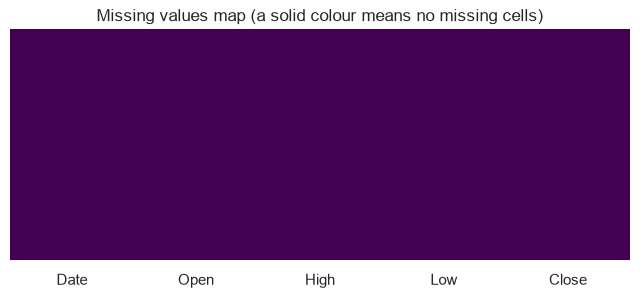

In [10]:
# Visualizing the missing values
plt.figure(figsize=(8, 3))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values map (a solid colour means no missing cells)")
plt.show()

### What did you know about your dataset?

- The dataset has **185 rows and 5 columns**: one row per month from **Jul-2005 to Nov-2020** (about 15 years).
- There are **no missing values and no duplicate rows**, and every month appears once, in order.
- `Date` is stored as text (e.g. `Jul-05`) and is converted to a datetime; Open, High, Low, Close are numeric (INR).
- The price logic is consistent: no month has Low above High, or Open/Close outside the High-Low range.
- Prices are right-skewed (mean Rs 105 vs median Rs 62.5) and range from Rs 9.98 (Mar-2009 close) to Rs 367.9 (Jul-2018 close).
- Open, High, Low and Close are all correlated at 0.98 or higher, so multicollinearity must be handled.
- The series has a structural break around Sep-2018, so the data covers very different market regimes.

## ***2. Understanding Your Variables***

In [11]:
# Dataset Columns
print(list(df.columns))

['Date', 'Open', 'High', 'Low', 'Close']


In [12]:
# Dataset Describe
df.describe().round(2)

,Open,High,Low,Close
count,185.00,185.00,185.00,185.00
mean,105.54,116.10,94.95,105.20
std,98.88,106.33,91.22,98.58
min,10.00,11.24,5.55,9.98
25%,33.80,36.14,28.51,33.45
50%,62.98,72.55,58.00,62.54
75%,153.00,169.19,138.35,153.30
max,369.95,404.00,345.50,367.90


### Variables Description

| Variable | Meaning (monthly values) |
|---|---|
| **Date** | Month of the record (stored as text like `Jul-05`; converted to a real date in wrangling) |
| **Open** | Price at the start of the month (INR) |
| **High** | Highest price reached during the month (INR) |
| **Low** | Lowest price reached during the month (INR) |
| **Close** | Price at the end of the month (INR) — **the target variable** |

*Note: the project brief describes High/Low as "in the day" and Close as "occupations of the speaker"; both are typos in the brief.
The file has one row per month, so every value is a monthly figure.*

### Check Unique Values for each variable.

In [13]:
# Check Unique Values for each variable.
for col in df.columns:
    print(f"{col:6s} -> {df[col].nunique()} unique values")

Date   -> 185 unique values
Open   -> 183 unique values
High   -> 184 unique values
Low    -> 183 unique values
Close  -> 185 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [14]:
# Write your code to make your dataset analysis ready.
def wrangle(raw):
    """Parse dates, sort chronologically and add analysis columns (returns, ranges, moving averages)."""
    out = raw.copy()
    out["Date"] = pd.to_datetime(out["Date"], format="%b-%y")       # 'Jul-05' -> 2005-07-01
    out = out.sort_values("Date").reset_index(drop=True)
    out["Year"] = out["Date"].dt.year
    out["Month"] = out["Date"].dt.month
    out["Return"] = out["Close"].pct_change()                        # month-over-month % change in Close
    out["Range_pct"] = (out["High"] - out["Low"]) / out["Open"]      # monthly price swing relative to Open
    out["MA3"] = out["Close"].rolling(3).mean()                      # 3-month moving average
    out["MA12"] = out["Close"].rolling(12).mean()                    # 12-month moving average
    out["Volatility12"] = out["Return"].rolling(12).std()            # rolling 12-month volatility
    return out

data = wrangle(df)

# Sanity checks on price logic: Low <= Open, Close <= High etc. Count of violating rows must be 0.
bad = ((data.High < data.Low) | (data.Open > data.High) | (data.Open < data.Low) |
       (data.Close > data.High) | (data.Close < data.Low)).sum()
print("Rows violating OHLC logic:", bad)
print("Chronological & unique months:", data["Date"].is_monotonic_increasing and data["Date"].is_unique)
print("Date range:", data["Date"].min().date(), "to", data["Date"].max().date())
data.head()

Rows violating OHLC logic: 0
Chronological & unique months: True
Date range: 2005-07-01 to 2020-11-01


,Date,Open,High,Low,Close,Year,Month,Return,Range_pct,MA3,MA12,Volatility12
0,2005-07-01,13.00,14.00,11.25,12.46,2005,7,NaN,0.211538,NaN,NaN,NaN
1,2005-08-01,12.58,14.88,12.55,13.42,2005,8,0.077047,0.185215,NaN,NaN,NaN
2,2005-09-01,13.48,14.87,12.27,13.30,2005,9,-0.008942,0.192878,13.060000,NaN,NaN
3,2005-10-01,13.20,14.47,12.40,12.99,2005,10,-0.023308,0.156818,13.236667,NaN,NaN
4,2005-11-01,13.35,13.88,12.88,13.41,2005,11,0.032333,0.074906,13.233333,NaN,NaN


### What all manipulations have you done and insights you found?

**What I did**
1. Converted `Date` from text to a real datetime (`%b-%y`) and sorted the data chronologically.
2. Added analysis columns: Year, Month, month-over-month Return, Range_pct = (High - Low) / Open, 3- and 12-month moving averages and 12-month rolling volatility.
3. Checked price logic (0 rows violate Low <= Open/Close <= High) and confirmed unique, ordered months.

**What I found**
- The data is clean, with nothing to impute or remove.
- The price rose about 29x from Jul-2005 to Jul-2018 and then fell about 97% by Jul-2020.
- Monthly returns average +1.5% but swing between -53% and +70%.
- The typical monthly High-Low range is about 19% of the Open price.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

### Univariate Analysis

#### Chart - 1 - Closing price over time

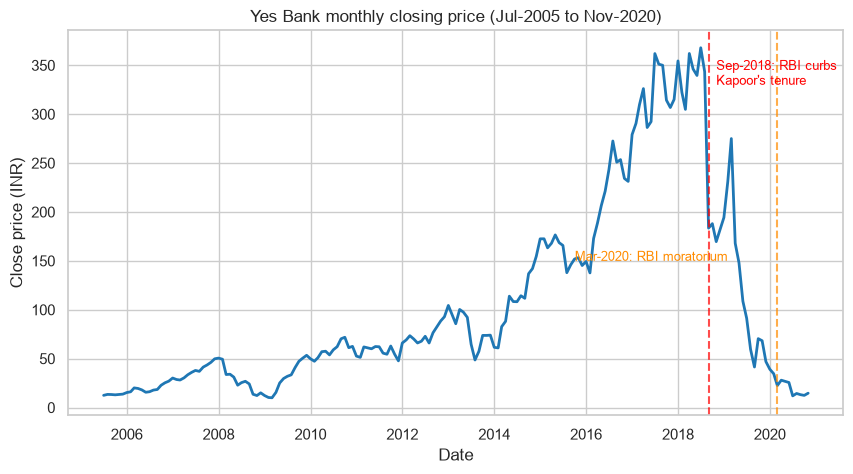

In [15]:
# Chart - 1 visualization code
fig, ax = plt.subplots()
ax.plot(data["Date"], data["Close"], color="#1f77b4", lw=2)
ax.axvline(pd.Timestamp("2018-09-01"), color="red", ls="--", alpha=.7)
ax.text(pd.Timestamp("2018-11-01"), 330, "Sep-2018: RBI curbs\nKapoor's tenure", color="red", fontsize=9)
ax.axvline(pd.Timestamp("2020-03-01"), color="darkorange", ls="--", alpha=.7)
ax.text(pd.Timestamp("2019-02-01"), 150, "Mar-2020: RBI moratorium", color="darkorange", fontsize=9, ha="right")
ax.set_title("Yes Bank monthly closing price (Jul-2005 to Nov-2020)")
ax.set_xlabel("Date"); ax.set_ylabel("Close price (INR)")
plt.show()

##### 1. Why did you pick the specific chart?

A line chart is the natural choice for a time-ordered series: it shows trend, turning points and shocks in one picture.

##### 2. What is/are the insight(s) found from the chart?

The price climbed from about Rs 12.5 (Jul-2005) to a peak of Rs 367.9 (Jul-2018), then fell roughly 97% to Rs 11.95 (Jul-2020). Earlier drawdowns are visible in 2008-09 (global financial crisis) and mid-2013. The steep fall begins right around the Sep-2018 event and continues through the Mar-2020 moratorium. The series has clear regimes, so no single stable relationship holds for the whole period.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the chart shows that long growth phases (2009-2017) are possible and that the model must be checked on different regimes. **Negative:** the 2018-2020 collapse shows how fast governance problems destroy value (about 97% in two years). For modelling it means the test period is very different from most of the training period, so metrics there are a hard, honest test.

#### Chart - 2 - Distribution of closing price

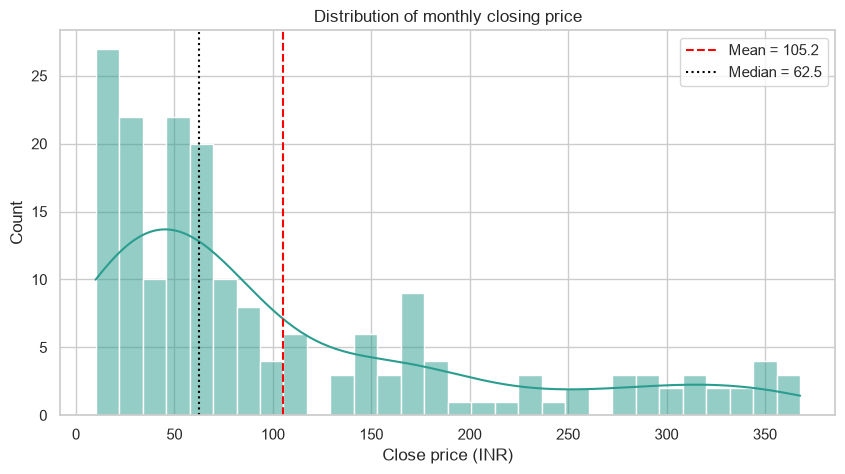

Skewness of Close: 1.26


In [16]:
# Chart - 2 visualization code
fig, ax = plt.subplots()
sns.histplot(data["Close"], bins=30, kde=True, ax=ax, color="#2a9d8f")
ax.axvline(data["Close"].mean(), color="red", ls="--", label=f"Mean = {data['Close'].mean():.1f}")
ax.axvline(data["Close"].median(), color="black", ls=":", label=f"Median = {data['Close'].median():.1f}")
ax.set_title("Distribution of monthly closing price"); ax.set_xlabel("Close price (INR)"); ax.legend()
plt.show()
print("Skewness of Close:", round(data["Close"].skew(), 2))

##### 1. Why did you pick the specific chart?

A histogram with a density curve shows the shape of the target variable (skew, spread, typical range), which decides if a transformation is needed.

##### 2. What is/are the insight(s) found from the chart?

The distribution is right-skewed (skewness about 1.26): the mean (Rs 105) is well above the median (Rs 62.5) and most months closed below Rs 150, with a thin tail of high-price months in 2016-2018.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the skew is a clear reason to model the logarithm of price, which stabilises errors across low and high price levels. **Negative:** a model trained on raw prices would be dominated by the few very high-price months and would make poor percentage errors in the low-price era.

#### Chart - 3 - Box plots of Open, High, Low and Close

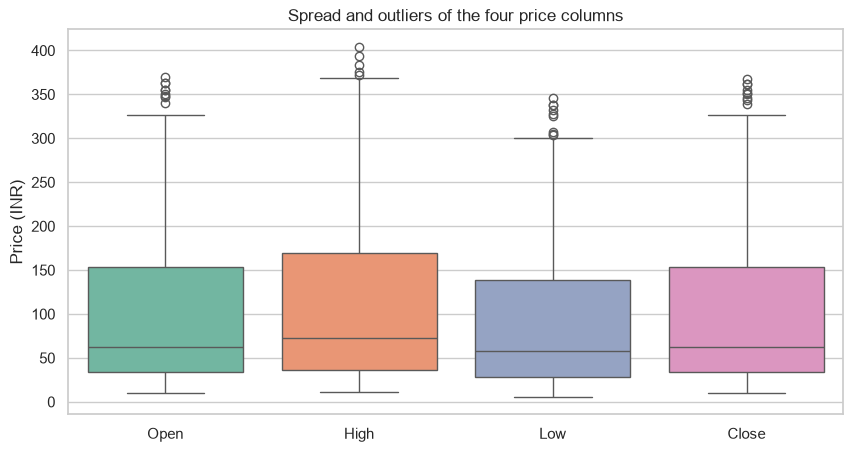

In [17]:
# Chart - 3 visualization code
fig, ax = plt.subplots()
sns.boxplot(data=data[["Open", "High", "Low", "Close"]], ax=ax, palette="Set2")
ax.set_title("Spread and outliers of the four price columns"); ax.set_ylabel("Price (INR)")
plt.show()

##### 1. Why did you pick the specific chart?

Box plots show median, spread and statistical outliers for several variables side by side.

##### 2. What is/are the insight(s) found from the chart?

All four price columns have almost the same shape: High has the highest median (about Rs 72.6), Low the lowest (about Rs 58). The IQR rule flags the 2017-2018 peak months as upper outliers. These are real market prices rather than data errors.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the four columns move together, so they carry consistent information for the model. **Negative:** blindly deleting the 'outliers' would remove the most important period of the story (the peak before the crash), so they are kept and handled by the log transform instead.

#### Chart - 4 - Distribution of monthly returns

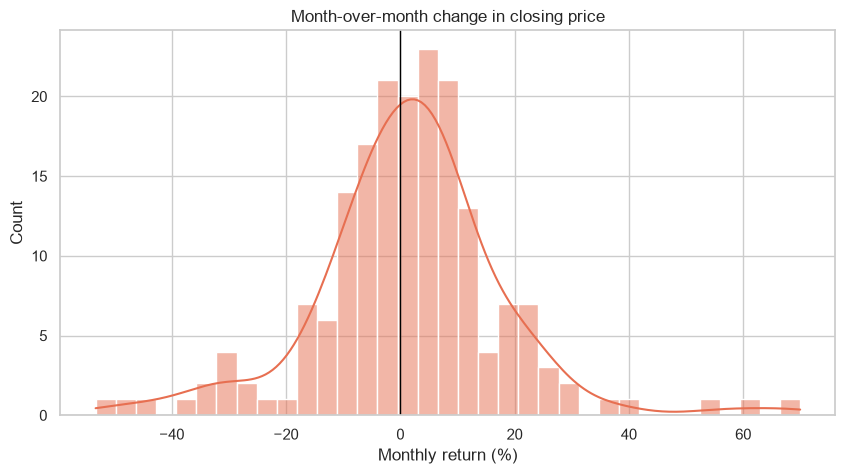

count    184.000
mean       0.015
std        0.165
min       -0.533
25%       -0.056
50%        0.022
75%        0.084
max        0.700
Name: Return, dtype: float64


In [18]:
# Chart - 4 visualization code
fig, ax = plt.subplots()
sns.histplot(data["Return"].dropna() * 100, bins=35, kde=True, ax=ax, color="#e76f51")
ax.axvline(0, color="black", lw=1)
ax.set_title("Month-over-month change in closing price"); ax.set_xlabel("Monthly return (%)")
plt.show()
print(data["Return"].describe().round(3))

##### 1. Why did you pick the specific chart?

Returns (percentage change) put every month on the same scale, so a histogram shows the real risk profile independent of price level.

##### 2. What is/are the insight(s) found from the chart?

The average monthly return is about +1.5% but the standard deviation is about 16.5%, with extremes from -53.3% (Jul-2020) to +70.0% (Oct-2019). Tails are heavy, so the returns are not normally distributed.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** knowing typical swings of +/-16% per month helps set realistic expectations for any forecasting error. **Negative:** such large swings mean even a good model will occasionally miss a month by a large margin, so predictions should never be used alone for trading decisions.

### Bivariate Analysis

#### Chart - 5 - Average closing price by year

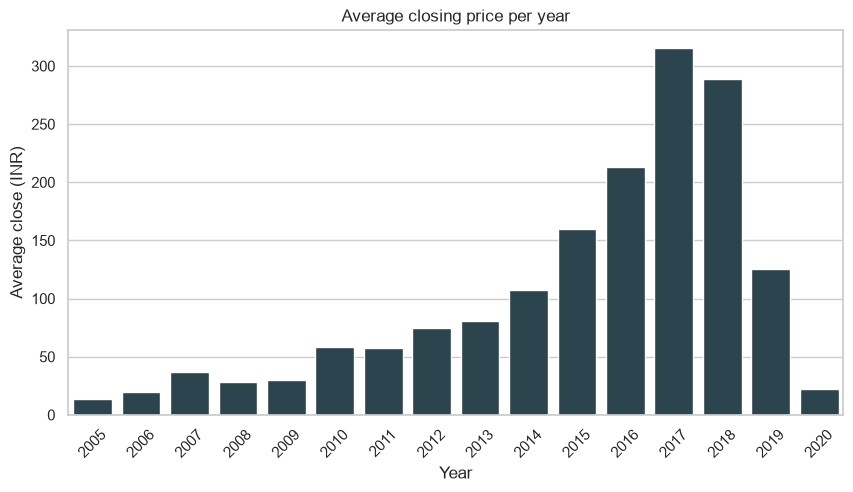

In [19]:
# Chart - 5 visualization code (Categorical - Numerical)
yearly = data.groupby("Year")["Close"].mean()
fig, ax = plt.subplots()
sns.barplot(x=yearly.index, y=yearly.values, ax=ax, color="#264653")
ax.set_title("Average closing price per year"); ax.set_ylabel("Average close (INR)"); ax.set_xlabel("Year")
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart compares a summary value across a small set of categories (years) very clearly.

##### 2. What is/are the insight(s) found from the chart?

The yearly average rose almost every year from 2009 to 2017 (only 2011 dipped slightly) and peaked in 2017 at about Rs 315. After that it fell sharply: Rs 289 (2018), Rs 125 (2019) and Rs 22 (2020), the lowest annual level since 2006.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a long, steady growth phase is evidence of earlier healthy business performance. **Negative:** two consecutive years of falling averages (2019, 2020) signal lost investor confidence, which the bank would need a credible recovery plan to reverse.

#### Chart - 6 - Close price spread by year

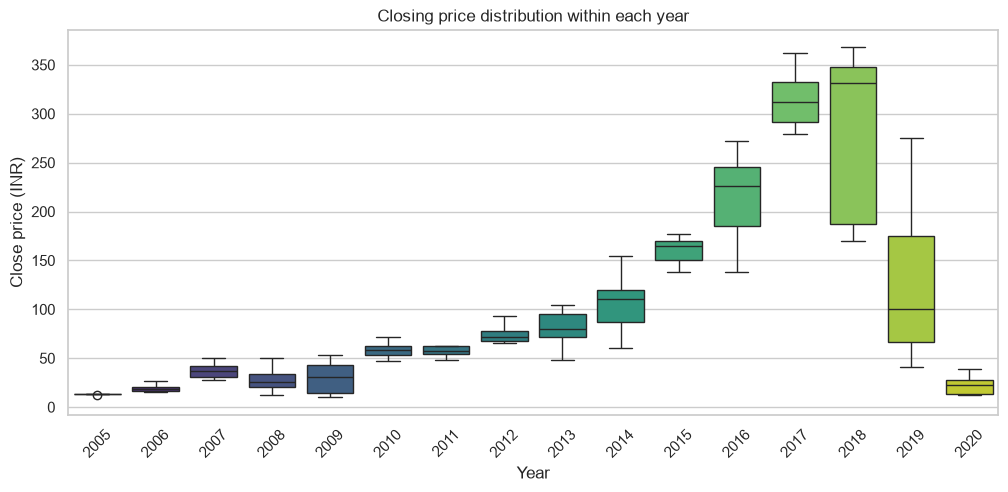

In [20]:
# Chart - 6 visualization code (Categorical - Numerical)
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(x="Year", y="Close", data=data, ax=ax, palette="viridis")
ax.set_title("Closing price distribution within each year"); ax.set_ylabel("Close price (INR)")
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

Box plots per year show not only the level but also how much the price moved inside each year.

##### 2. What is/are the insight(s) found from the chart?

Within-year spread was very wide in 2013, 2016 and 2018, and especially 2019 (about Rs 41 to Rs 275), meaning the price moved by several multiples inside one year. Years such as 2005, 2011 and 2020 were comparatively narrow.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** calm years show that stable periods exist and a stable model is possible there. **Negative:** the very wide 2018-2019 ranges show high uncertainty, which raises the risk of holding the stock and makes forecasting harder.

#### Chart - 7 - Average monthly return by calendar month

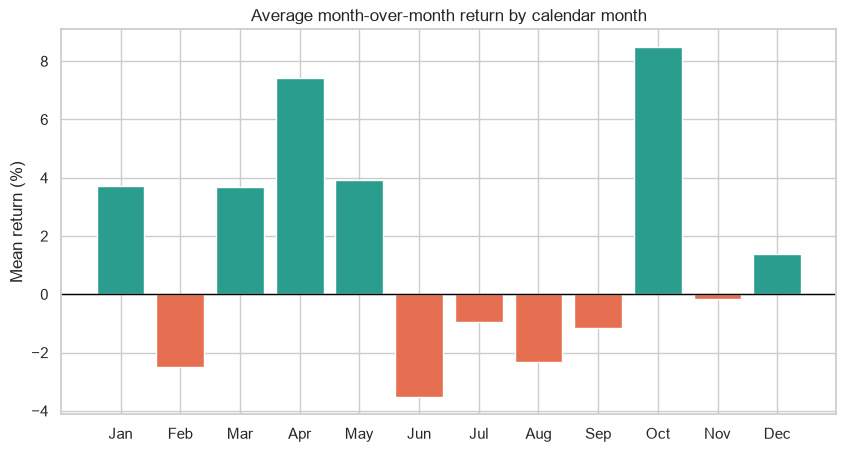

In [21]:
# Chart - 7 visualization code (Categorical - Numerical)
month_ret = data.groupby("Month")["Return"].mean() * 100
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots()
colors = ["#2a9d8f" if v > 0 else "#e76f51" for v in month_ret.values]
ax.bar(month_names, month_ret.values, color=colors)
ax.axhline(0, color="black", lw=1)
ax.set_title("Average month-over-month return by calendar month"); ax.set_ylabel("Mean return (%)")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart with positive/negative colouring is the clearest way to compare seasonality across 12 categories.

##### 2. What is/are the insight(s) found from the chart?

October (+8.5%) and April (+7.4%) show the highest average returns, June (-3.5%), February (-2.5%) and August (-2.3%) the lowest. However each month has only 15-16 observations and returns vary by 9-23% within a month, so this pattern is likely noise (formally tested in Hypothesis 3).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** none that is reliable. **Negative:** acting on this seasonality could lead to wrong decisions, because the pattern is not statistically significant. It is therefore not used as a model feature.

#### Chart - 8 - Open vs Close

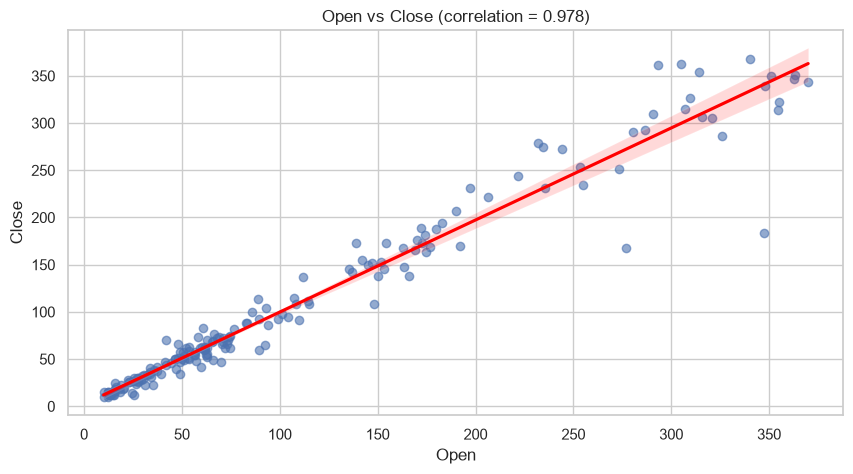

In [22]:
# Chart - 8 visualization code (Numerical - Numerical)
fig, ax = plt.subplots()
sns.regplot(x="Open", y="Close", data=data, ax=ax, scatter_kws={"alpha": .6}, line_kws={"color": "red"})
ax.set_title(f"Open vs Close (correlation = {data['Open'].corr(data['Close']):.3f})")
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot with a fitted line shows the strength and shape of the relationship between two numeric variables.

##### 2. What is/are the insight(s) found from the chart?

Open and Close have a very strong linear relationship (correlation about 0.978). The spread around the line widens at higher prices.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the opening price alone is already a strong predictor of the closing price. **Negative:** the widening spread means absolute errors will be larger in high-price months, which is another reason to model in log scale.

#### Chart - 9 - High vs Close

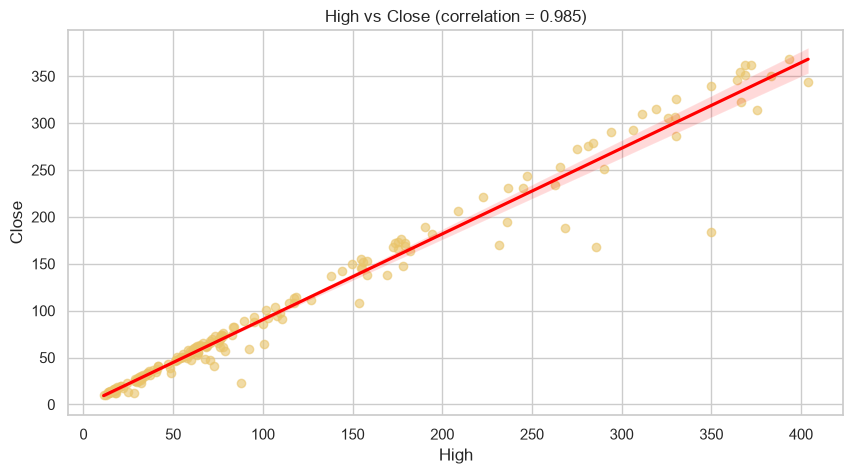

In [23]:
# Chart - 9 visualization code (Numerical - Numerical)
fig, ax = plt.subplots()
sns.regplot(x="High", y="Close", data=data, ax=ax, color="#e9c46a", scatter_kws={"alpha": .6}, line_kws={"color": "red"})
ax.set_title(f"High vs Close (correlation = {data['High'].corr(data['Close']):.3f})")
plt.show()

##### 1. Why did you pick the specific chart?

Same chart type as Chart 8 so that the three price predictors can be compared fairly.

##### 2. What is/are the insight(s) found from the chart?

High and Close are even more tightly related (correlation about 0.985): the month's close is never above its high, and usually sits close to it in rising months.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** High is very informative. **Negative (important):** the monthly High is only known once the month ends, so a model using it is a nowcasting tool and not a true forecast of the future. This limitation is noted in the conclusion.

#### Chart - 10 - Low vs Close

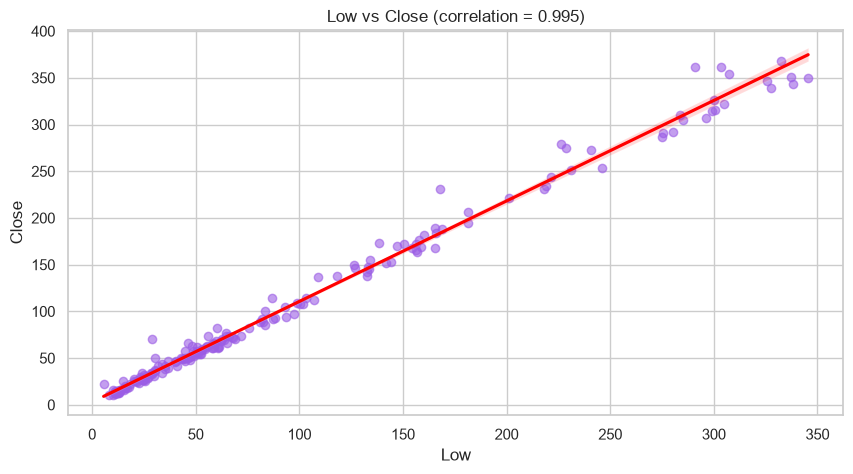

In [24]:
# Chart - 10 visualization code (Numerical - Numerical)
fig, ax = plt.subplots()
sns.regplot(x="Low", y="Close", data=data, ax=ax, color="#9b5de5", scatter_kws={"alpha": .6}, line_kws={"color": "red"})
ax.set_title(f"Low vs Close (correlation = {data['Low'].corr(data['Close']):.3f})")
plt.show()

##### 1. Why did you pick the specific chart?

Completes the comparison of Open, High and Low with the target.

##### 2. What is/are the insight(s) found from the chart?

Low has the strongest relationship with Close (correlation about 0.995), tighter than Open (0.978) and High (0.985). In falling months the close tends to be near the low of the month.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the model can reach high accuracy using these variables. **Negative:** like High, Low is only known at month end, and the three price columns are strongly correlated with each other, which causes multicollinearity (addressed in feature engineering by using ratios relative to Open, and checked with VIF).

#### Chart - 11 - Monthly price swing over time

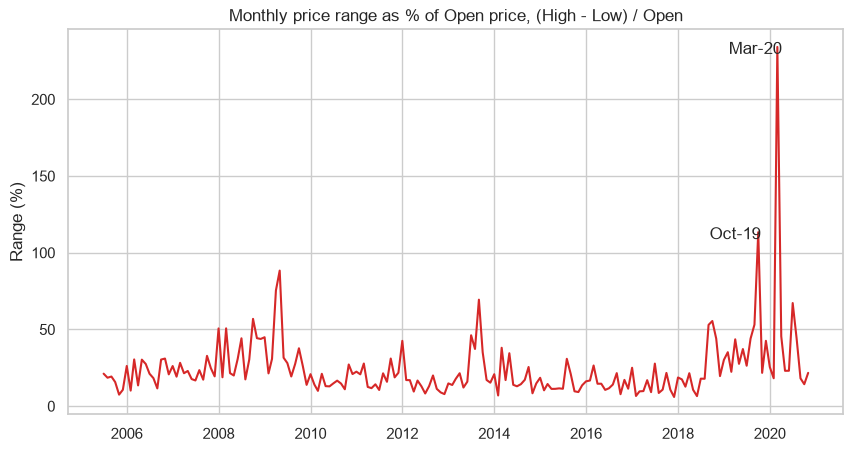

In [25]:
# Chart - 11 visualization code (Numerical over time)
fig, ax = plt.subplots()
ax.plot(data["Date"], data["Range_pct"] * 100, color="#d62828")
ax.set_title("Monthly price range as % of Open price, (High - Low) / Open"); ax.set_ylabel("Range (%)")
top = data.nlargest(2, "Range_pct")
for _, r in top.iterrows():
    ax.annotate(r["Date"].strftime("%b-%y"), (r["Date"], r["Range_pct"] * 100), textcoords="offset points", xytext=(-35, -5))
plt.show()

##### 1. Why did you pick the specific chart?

A line chart of the monthly range shows how risky each month was, independent of the price level.

##### 2. What is/are the insight(s) found from the chart?

The typical month has a High-Low range of about 19% of the opening price. The extreme months are Mar-2020 (about 234%, price touched Rs 5.55 and Rs 87.95 in the same month) and Oct-2019 (about 113%), plus 2009 recovery months.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a range indicator can serve as an early warning risk signal for the bank and investors. **Negative:** the extreme months show panic-level instability that drives down confidence and makes the month's close almost unpredictable.

#### Chart - 12 - Close vs moving averages

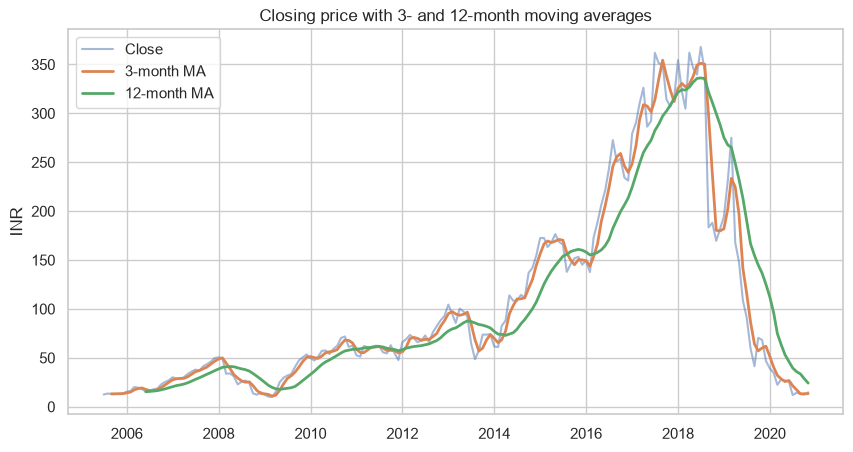

In [26]:
# Chart - 12 visualization code
fig, ax = plt.subplots()
ax.plot(data["Date"], data["Close"], label="Close", alpha=.5)
ax.plot(data["Date"], data["MA3"], label="3-month MA", lw=2)
ax.plot(data["Date"], data["MA12"], label="12-month MA", lw=2)
ax.set_title("Closing price with 3- and 12-month moving averages"); ax.set_ylabel("INR"); ax.legend()
plt.show()

##### 1. Why did you pick the specific chart?

Moving averages smooth the noise and reveal the trend; the project architecture also asks for moving-average analysis.

##### 2. What is/are the insight(s) found from the chart?

The 12-month average lags the price: it peaked in Jul-2018 (about Rs 336) and was still near Rs 322 in Sep-2018 when the Close had already dropped to Rs 183. The 3-month average reacts faster but still lags the sharp fall.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** moving averages are useful, simple, interpretable trend features (last close relative to its 3-month average is used as a model feature). **Negative:** being lagging indicators, they would have warned late on the 2018 crash.

#### Chart - 13 - Rolling 12-month volatility

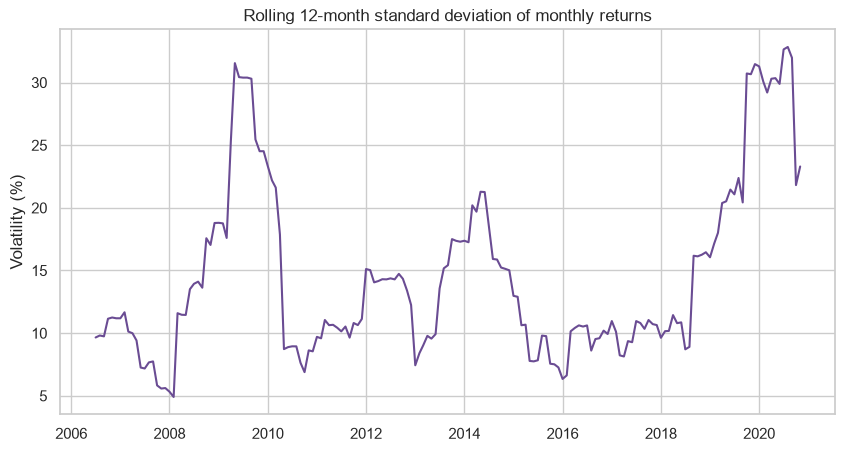

Highest: Aug-2020 | Median: 11.4 %


In [27]:
# Chart - 13 visualization code
fig, ax = plt.subplots()
ax.plot(data["Date"], data["Volatility12"] * 100, color="#6a4c93")
ax.set_title("Rolling 12-month standard deviation of monthly returns"); ax.set_ylabel("Volatility (%)")
plt.show()
print("Highest:", data.loc[data["Volatility12"].idxmax(), "Date"].strftime("%b-%Y"), "| Median:", round(data["Volatility12"].median() * 100, 1), "%")

##### 1. Why did you pick the specific chart?

Rolling volatility shows how risk changes over time, which is a key aspect of stock behaviour.

##### 2. What is/are the insight(s) found from the chart?

Volatility peaks in 2020 at about 33% (Aug-2020) against a long-run median of about 11%. Similar peaks of about 32% appear in 2009 and 2019. Risk is not constant: it rises sharply in crises.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** can be used as a risk-monitoring KPI. **Negative:** the model's accuracy is expected to fall in high-volatility periods, so error should be monitored alongside volatility.

### Multivariate Analysis

#### Chart - 14 - Correlation Heatmap

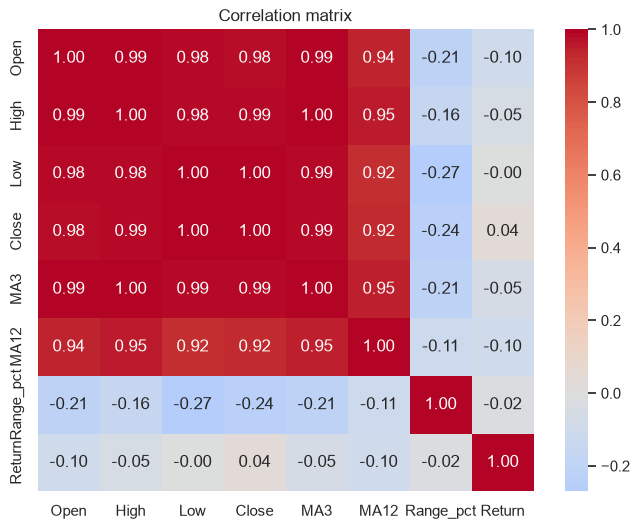

In [28]:
# Correlation Heatmap visualization code
fig, ax = plt.subplots(figsize=(8, 6))
corr = data[["Open", "High", "Low", "Close", "MA3", "MA12", "Range_pct", "Return"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap summarises all pairwise correlations at once and quickly highlights redundant variables.

##### 2. What is/are the insight(s) found from the chart?

Open, High, Low and Close are all correlated at 0.98 or higher, with the moving averages as well. Return and Range_pct are almost uncorrelated with price level, which means they carry separate (non-price-level) information.

#### Chart - 15 - Pair Plot

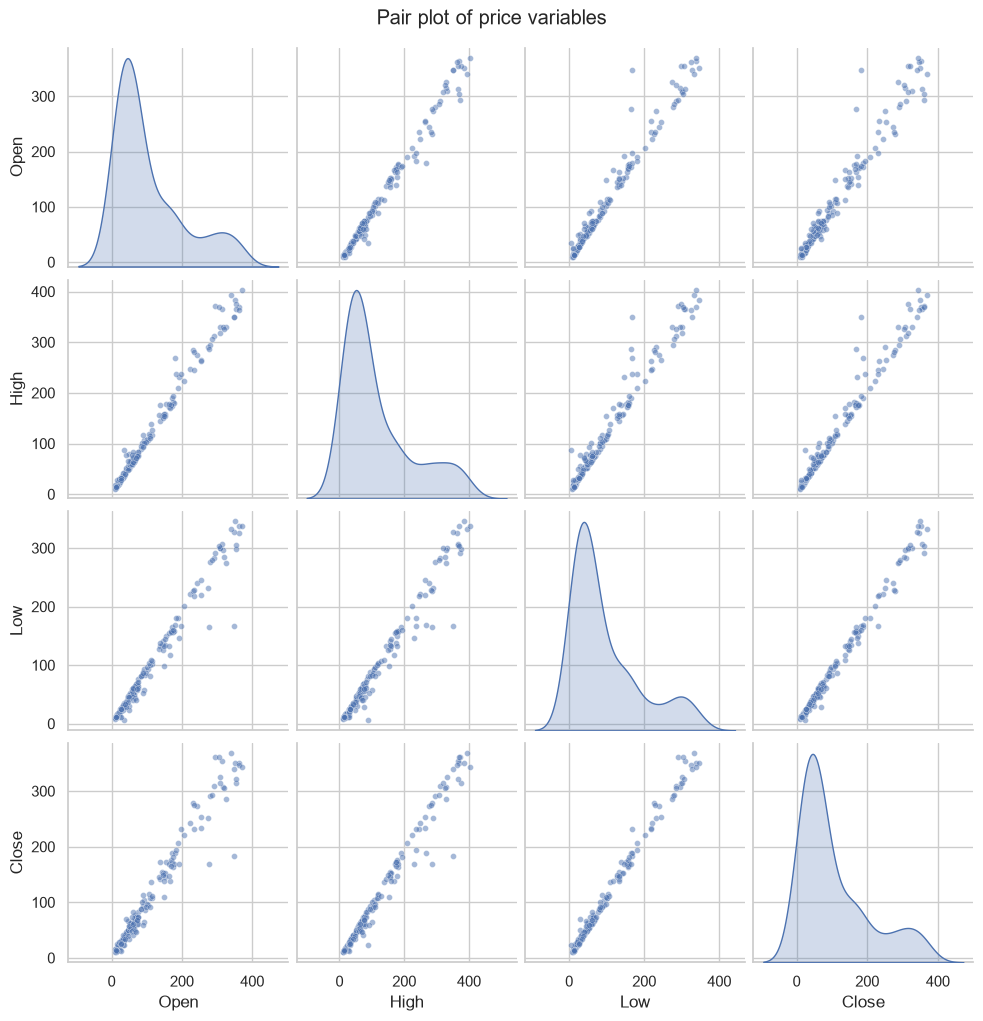

In [29]:
# Pair Plot visualization code
sns.pairplot(data[["Open", "High", "Low", "Close"]], diag_kind="kde", plot_kws={"alpha": .5, "s": 18})
plt.suptitle("Pair plot of price variables", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every bivariate relationship and each distribution in one grid.

##### 2. What is/are the insight(s) found from the chart?

All pairs of the price columns lie on tight straight lines, confirming strong multicollinearity, and all four distributions are right-skewed in the same way. A linear model should work well after a log transform.

### Additional charts

#### Chart - 16 - Close vs previous month's Close

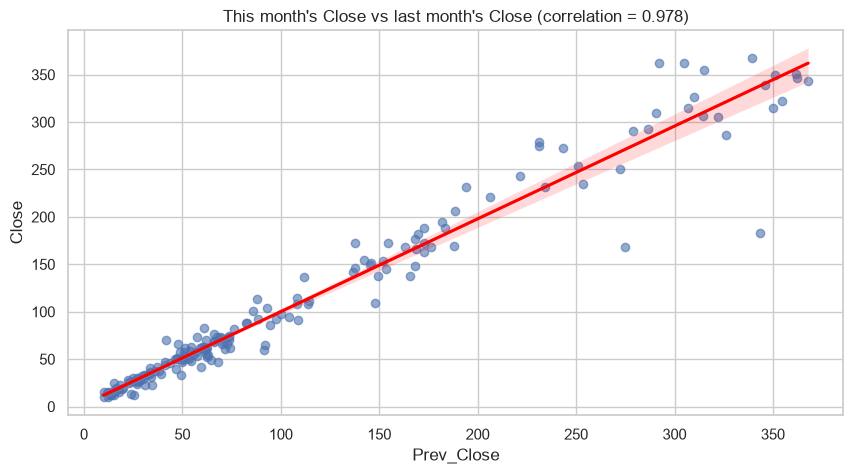

In [30]:
# Chart - 16 visualization code (autocorrelation check)
lag = data[["Close"]].assign(Prev_Close=data["Close"].shift(1)).dropna()
fig, ax = plt.subplots()
sns.regplot(x="Prev_Close", y="Close", data=lag, ax=ax, scatter_kws={"alpha": .6}, line_kws={"color": "red"})
ax.set_title(f"This month's Close vs last month's Close (correlation = {lag['Close'].corr(lag['Prev_Close']):.3f})")
plt.show()

##### 1. Why did you pick the specific chart?

A lag scatter is the quickest way to see whether the past price helps predict the present one.

##### 2. What is/are the insight(s) found from the chart?

The correlation between this month's and last month's Close is about 0.978, so price has strong persistence. Previous Close is therefore a valuable feature.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** lag features allow the model to work even when the current month's High/Low is not yet known. **Negative:** high persistence on trending data can overstate real predictive skill, because a naive 'same as last month' guess already looks good. We compare against such naive baselines.

#### Chart - 17 - Monthly returns before vs after Sep-2018

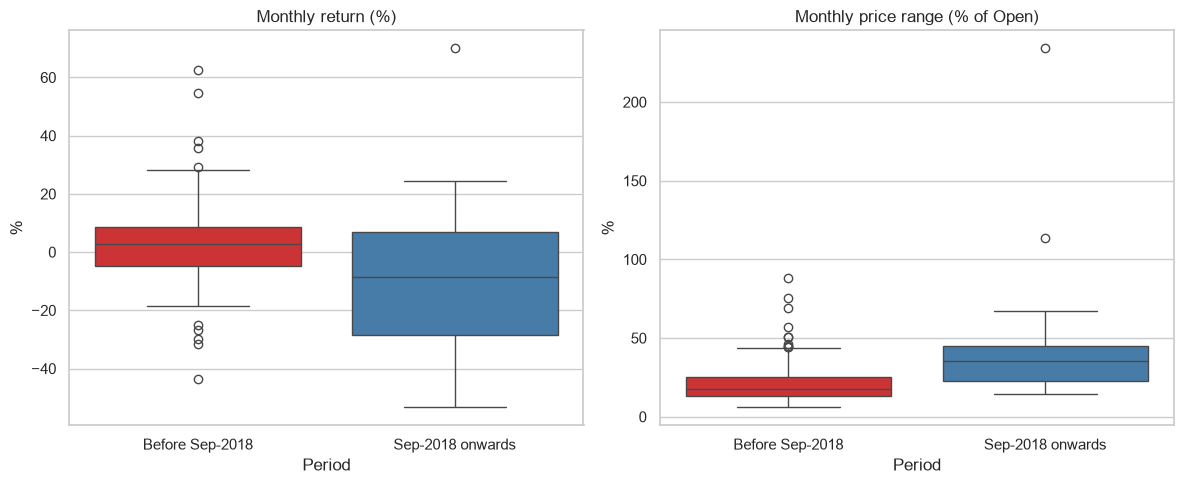

                  Return  Range_pct
Period                             
Before Sep-2018    0.028      0.175
Sep-2018 onwards  -0.085      0.352


In [31]:
# Chart - 17 visualization code
data["Period"] = np.where(data["Date"] < pd.Timestamp("2018-09-01"), "Before Sep-2018", "Sep-2018 onwards")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(x="Period", y=data["Return"] * 100, data=data, ax=axes[0], palette="Set1")
axes[0].set_title("Monthly return (%)"); axes[0].set_ylabel("%")
sns.boxplot(x="Period", y=data["Range_pct"] * 100, data=data, ax=axes[1], palette="Set1")
axes[1].set_title("Monthly price range (% of Open)"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()
print(data.groupby("Period")[["Return", "Range_pct"]].median().round(3))

##### 1. Why did you pick the specific chart?

A side-by-side box plot compares the return and risk profile of two periods, which directly addresses the business context (the fraud case from 2018).

##### 2. What is/are the insight(s) found from the chart?

Before Sep-2018 the median monthly return was about +2.9% and the median range about 17%. From Sep-2018 onwards the median return turned to about -8.5% and the median range doubled to about 35%. The stock became both weaker and more volatile.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the clear regime split gives a measurable way to monitor recovery (returns back above zero, range falling). **Negative:** the post-2018 period is far riskier, so models and investors should treat it separately. The change is formally tested in Hypotheses 1 and 2.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

1. Monthly returns **before** Sep-2018 are higher than monthly returns from Sep-2018 onwards (Chart 17).
2. Monthly price swings (High-Low range) are **larger** from Sep-2018 onwards than before (Charts 11 and 17).
3. Average monthly returns **differ across calendar months**, i.e. there is seasonality (Chart 7).

All tests use a 5% significance level (alpha = 0.05).

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** The distribution of monthly returns before Sep-2018 is the same as (or lower than) from Sep-2018 onwards.
**H1:** Monthly returns before Sep-2018 are higher than from Sep-2018 onwards.

#### 2. Perform an appropriate statistical test.

In [32]:
# Perform Statistical Test to obtain P-Value
ALPHA = 0.05
cut = pd.Timestamp("2018-09-01")
ret_pre = data.loc[(data["Date"] < cut) & data["Return"].notna(), "Return"]
ret_post = data.loc[data["Date"] >= cut, "Return"]

# Normality check (decides parametric vs non-parametric)
print("Shapiro-Wilk p-value on all returns:", stats.shapiro(data["Return"].dropna()).pvalue)

u_stat, p1 = stats.mannwhitneyu(ret_pre, ret_post, alternative="greater")
print(f"Mann-Whitney U = {u_stat:.0f}, p-value = {p1:.4f}")
print("Median return before:", round(ret_pre.median(), 4), "| after:", round(ret_post.median(), 4))
print("Reject H0" if p1 < ALPHA else "Fail to reject H0")
# Cross-check with a parametric Welch t-test (one-sided); heavy tails make it less reliable than the rank test above
print("Welch t-test p-value (for comparison):", round(stats.ttest_ind(ret_pre, ret_post, equal_var=False, alternative="greater").pvalue, 4))

Shapiro-Wilk p-value on all returns: 5.721820573889643e-07
Mann-Whitney U = 2825, p-value = 0.0029
Median return before: 0.0285 | after: -0.0849
Reject H0
Welch t-test p-value (for comparison): 0.0267


##### Which statistical test have you done to obtain P-Value?

Mann-Whitney U test (one-sided).

##### Why did you choose the specific statistical test?

The two groups are independent samples (different months). A Shapiro-Wilk test on the returns gave p < 0.001, so they are not normally distributed, and the after-Sep-2018 group has only 27 months. A rank-based **Mann-Whitney U test** needs no normality assumption, so it is the safer choice. **Result:** p = 0.0029 < 0.05, so we **reject H0**: returns before Sep-2018 were significantly higher (median +2.9% vs -8.5% per month). The parametric Welch t-test printed for comparison (one-sided) gives p of about 0.027, which leads to the same conclusion; the rank-based test is still the primary result because of the heavy tails and the small after-period group.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** The monthly price range (% of Open) from Sep-2018 onwards is not larger than before.
**H1:** The monthly price range from Sep-2018 onwards is larger than before.

#### 2. Perform an appropriate statistical test.

In [33]:
# Perform Statistical Test to obtain P-Value
rng_pre = data.loc[data["Date"] < cut, "Range_pct"]
rng_post = data.loc[data["Date"] >= cut, "Range_pct"]

u_stat, p2 = stats.mannwhitneyu(rng_post, rng_pre, alternative="greater")
print(f"Mann-Whitney U = {u_stat:.0f}, p-value = {p2:.2e}")
print("Median range before:", round(rng_pre.median(), 3), "| after:", round(rng_post.median(), 3))
print("Reject H0" if p2 < ALPHA else "Fail to reject H0")

Mann-Whitney U = 3483, p-value = 7.69e-08
Median range before: 0.175 | after: 0.352
Reject H0


##### Which statistical test have you done to obtain P-Value?

Mann-Whitney U test (one-sided).

##### Why did you choose the specific statistical test?

Range_pct is skewed, with extreme months such as Mar-2020, and we compare two independent groups, so the non-parametric **Mann-Whitney U test** is appropriate (one-sided, since the hypothesis is that risk increased). **Result:** p of about 8e-8 < 0.05, so we **reject H0**: monthly price swings became significantly larger after Sep-2018 (median range 17.5% of Open before vs 35.2% after, roughly double).

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** Monthly returns have the same distribution in all 12 calendar months (no seasonality).
**H1:** At least one calendar month has a different return distribution.

#### 2. Perform an appropriate statistical test.

In [34]:
# Perform Statistical Test to obtain P-Value
groups = [grp["Return"].dropna().values for _, grp in data.groupby("Month")]
h_stat, p3 = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {h_stat:.2f}, p-value = {p3:.4f}")
print("Reject H0" if p3 < ALPHA else "Fail to reject H0 (no significant seasonality)")

Kruskal-Wallis H = 12.38, p-value = 0.3356
Fail to reject H0 (no significant seasonality)


##### Which statistical test have you done to obtain P-Value?

Kruskal-Wallis H test.

##### Why did you choose the specific statistical test?

We compare monthly returns across **12 independent groups** (calendar months) that are not normally distributed, so the non-parametric **Kruskal-Wallis H test** (the rank-based alternative to one-way ANOVA) is appropriate. **Result:** p = 0.336 > 0.05, so we **fail to reject H0**: there is no statistically significant seasonality. The October and April highs seen in Chart 7 are most likely random noise from small samples (15-16 observations per month), so calendar month is not used as a feature.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [35]:
# Handling Missing Values & Missing Value Imputation
print("Missing values in the raw data:", int(df.isnull().sum().sum()))
# The raw data is complete, so no imputation is needed. Rows that become NaN later because of lag/rolling
# features (the first months) are dropped in build_features() rather than filled with made-up values.

Missing values in the raw data: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

The raw dataset has no missing values, so no imputation was required. The only NaNs appear in the first few rows after creating lag and rolling features (there is no earlier month to look back on). Those rows are dropped instead of imputed, because inventing values for a time series would leak or distort information.

### 2. Handling Outliers

In [36]:
# Handling Outliers & Outlier treatments
def iqr_outlier_count(series):
    q1, q3 = series.quantile([.25, .75]); iqr = q3 - q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum())

print("IQR outliers per column:")
for c in ["Open", "High", "Low", "Close", "Return", "Range_pct"]:
    print(f"  {c:10s}: {iqr_outlier_count(data[c].dropna())}")

# Treatment: keep the observations (they are genuine market events) and reduce their influence with a log transform
print("Skewness of Close before log:", round(data['Close'].skew(), 2), "| after log:", round(np.log(data['Close']).skew(), 2))

IQR outliers per column:
  Open      : 9
  High      : 5
  Low       : 9
  Close     : 9
  Return    : 15
  Range_pct : 12
Skewness of Close before log: 1.26 | after log: -0.03


##### What all outlier treatment techniques have you used and why did you use those techniques?

- **Detection:** the IQR rule (1.5 x IQR) flags 9 outliers in Open, 5 in High, 9 in Low, 9 in Close, 15 in monthly Return and 12 in Range_pct.
- **Treatment:** I **kept** them and reduced their influence with a **log transform** (skewness of Close drops from 1.26 to -0.03 after the log, and the model works on log-ratios).
- **Why not delete or cap them:** these are genuine market events (the 2017-18 peak, the 2018 fall, the Mar-2020 swing of about 234% of Open). With only 185 monthly rows, deleting them would remove the most important part of the story and make the model look better than it really is on the crash period.

### 3. Categorical Encoding

In [37]:
# Encode your categorical columns
cat_cols = df.select_dtypes(include="object").columns.tolist()
print("Text columns in raw file:", cat_cols)
# 'Date' is the only text column; it was converted to a datetime in wrangling. No categorical predictors exist.

Text columns in raw file: ['Date']


#### What all categorical encoding techniques have you used & why did you use those techniques?

No categorical encoding was needed: all predictors are numeric. The only text column (`Date`) was converted to a proper datetime. Calendar month was tested (Hypothesis 3) and found not to be significant, so it is not encoded as a feature.

### 4. Textual Data Preprocessing

Not applicable. This is a numeric time-series regression dataset with no text, so none of the NLP steps (contractions, tokenisation, stop-words, lemmatisation, POS tagging, vectorisation) are required.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [38]:
# Manipulate Features to minimize feature correlation and create new features
# Idea: raw Open/High/Low/Close are ~98% correlated with each other. Instead of feeding raw price levels,
# every feature is expressed RELATIVE to the month's Open, and the target is the Open-to-Close move.
def build_features(frame):
    """Create model features. Only information known at or before the month is used for lags (shifted).
    Target 'y' = ln(Close / Open). Rows with missing features (first months) are dropped."""
    out = frame[["Date", "Open", "High", "Low", "Close"]].sort_values("Date").reset_index(drop=True).copy()
    prev_close = out["Close"].shift(1)
    out["log_Open"] = np.log(out["Open"])                                         # price level (scale of the stock)
    out["hi_open"] = np.log(out["High"] / out["Open"])                            # how far price rose above Open
    out["lo_open"] = np.log(out["Low"] / out["Open"])                             # how far price fell below Open
    out["gap"] = np.log(out["Open"] / prev_close)                                 # gap between last close and this open
    out["trend3"] = np.log(prev_close / prev_close.rolling(3).mean())             # last close vs its 3-month average
    out["prev_ret"] = np.log(prev_close / out["Close"].shift(2))                  # last month's momentum
    out["y"] = np.log(out["Close"] / out["Open"])                                 # target: Open-to-Close log return
    feats = ["log_Open", "hi_open", "lo_open", "gap", "trend3", "prev_ret"]
    return out.dropna(subset=feats).reset_index(drop=True), feats

model_df, ALL_FEATURES = build_features(data)
print(model_df.shape)
print("Max |correlation| between raw prices Open/High/Low:", data[["Open", "High", "Low"]].corr().abs().where(lambda c: c < 1).max().max().round(3))
print("Max |correlation| between the engineered features:", model_df[ALL_FEATURES].corr().abs().where(lambda c: c < 1).max().max().round(3))

# Multicollinearity check with Variance Inflation Factor (VIF > 10 means strong collinearity)
X_vif = StandardScaler().fit_transform(model_df[ALL_FEATURES])
vif = pd.Series([variance_inflation_factor(X_vif, i) for i in range(X_vif.shape[1])], index=ALL_FEATURES)
print(vif.round(1).sort_values(ascending=False))
model_df.head()

(182, 12)
Max |correlation| between raw prices Open/High/Low: 0.993
Max |correlation| between the engineered features: 0.899
trend3      5.8
prev_ret    5.5
hi_open     1.2
log_Open    1.1
lo_open     1.1
gap         1.0
dtype: float64


,Date,Open,High,Low,Close,log_Open,hi_open,lo_open,gap,trend3,prev_ret,y
0,2005-10-01,13.20,14.47,12.40,12.99,2.580217,0.091861,-0.062520,-0.007547,0.018210,-0.008982,-0.016037
1,2005-11-01,13.35,13.88,12.88,13.41,2.591516,0.038933,-0.035841,0.027337,-0.018811,-0.023584,0.004484
2,2005-12-01,13.49,14.44,13.00,13.71,2.601949,0.068053,-0.036999,0.005948,0.013262,0.031821,0.016177
3,2006-01-01,13.68,17.16,13.58,15.33,2.615935,0.226646,-0.007337,-0.002191,0.025112,0.022125,0.113877
4,2006-02-01,15.50,16.97,15.40,16.12,2.740840,0.090607,-0.006473,0.011028,0.080097,0.111686,0.039221


#### 2. Feature Selection

In [39]:
# Select your features wisely to avoid overfitting
# Selection is judged on the TRAINING part only, to avoid leaking test information.
SPLIT = int(len(model_df) * 0.80)                      # chronological 80/20 split point
X_all, y_all = model_df[ALL_FEATURES], model_df["y"]
X_tr_sel, y_tr_sel = X_all.iloc[:SPLIT], y_all.iloc[:SPLIT]

# 1) Univariate F-score
f_scores, _ = f_regression(X_tr_sel, y_tr_sel)
# 2) Recursive Feature Elimination with a linear model
rfe = RFE(LinearRegression(), n_features_to_select=5).fit(StandardScaler().fit_transform(X_tr_sel), y_tr_sel)
# 3) Lasso: coefficients shrunk to zero are not useful
lasso = Lasso(alpha=0.001, max_iter=50000).fit(StandardScaler().fit_transform(X_tr_sel), y_tr_sel)

selection = pd.DataFrame({"F_score": f_scores.round(1), "RFE_selected": rfe.support_,
                          "Lasso_coef": lasso.coef_.round(4)}, index=ALL_FEATURES)
print(selection)

FEATURES = [f for f, keep in zip(ALL_FEATURES, rfe.support_) if keep]
print("\nFinal features:", FEATURES)

          F_score  RFE_selected  Lasso_coef
log_Open      0.5         False      0.0024
hi_open     161.2          True      0.0799
lo_open     182.5          True      0.0747
gap           2.2          True     -0.0103
trend3        2.4          True      0.0090
prev_ret      7.8          True      0.0000

Final features: ['hi_open', 'lo_open', 'gap', 'trend3', 'prev_ret']


##### What all feature selection methods have you used  and why?

Three methods were used, all on the **training period only** to avoid leaking test information:
1. **Univariate F-score** (f_regression) to rank each feature's linear relationship with the target.
2. **Recursive Feature Elimination (RFE)** with a linear model, keeping 5 of 6 features.
3. **Lasso regression** (L1), where useless features are pushed to zero.

In addition, **VIF** and correlation checks confirmed that the engineered features are far less collinear than the raw prices (maximum VIF 5.8 and maximum correlation 0.90, against 0.99 between raw Open, High and Low). RFE dropped `log_Open` (price level), and the other five features were kept.

##### Which all features you found important and why?

- **hi_open** (how far the month's High rose above the Open) and **lo_open** (how far the Low fell below the Open) are by far the most important: they have the highest F-scores (161 and 183) and the largest Lasso coefficients (about 0.08 and 0.075). They describe the month's trading range, which tells where the Close can end.
- **trend3, prev_ret and gap** (previous close vs its 3-month average, last month's momentum, and the gap between last close and this open) carry small but non-zero information about direction and were kept.
- **log_Open** (price level) was dropped because the target is already measured relative to Open, so the level adds almost nothing.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes. Prices are right-skewed (skewness about 1.26) and the error spread grows with the price level (Charts 2 and 8). I used **log transforms**: the target is ln(Close / Open), the month's Open-to-Close move on a percentage scale, and all other price features are log-ratios (for example ln(High / Open)) plus ln(Open) for the price level. The target no longer trends with the price level (it is centred close to zero), the relationships become more linear, and the model optimises percentage error, which is fair across the Rs 10 to Rs 370 range. Predictions are converted back with `Close = Open * exp(prediction)` so that all metrics are reported in rupees.

In [40]:
# Transform Your data (log transform already applied inside build_features; here we verify the effect)
print("Skewness  Close:", round(data['Close'].skew(), 2), "->  target ln(Close/Open):", round(model_df['y'].skew(), 2))

Skewness  Close: 1.26 ->  target ln(Close/Open): -1.03


### 6. Data Scaling

In [41]:
# Scaling your data: StandardScaler is placed INSIDE each model pipeline, so it is fitted only on training folds (no leakage).
scaler_demo = StandardScaler().fit(model_df[FEATURES].iloc[:SPLIT])
print(pd.DataFrame(scaler_demo.transform(model_df[FEATURES].iloc[:SPLIT]), columns=FEATURES).describe().loc[["mean", "std"]].round(2))

      hi_open  lo_open  gap  trend3  prev_ret
mean     -0.0     -0.0  0.0     0.0       0.0
std       1.0      1.0  1.0     1.0       1.0


##### Which method have you used to scale you data and why?

**StandardScaler** (zero mean, unit variance). Linear/Ridge models need scaled inputs so that regularisation treats all features fairly, and the features mix very different ranges (log prices around 2-6, percentage ratios around 0-2). It is fitted inside a `Pipeline` on the training data only, so no test information leaks. Tree models do not need scaling but are unaffected by it.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Not required. There are only 6 features and about 150 training rows. PCA would show that the price features are nearly one dimension (see below), but PCA components are harder to explain to a business reader, while Ridge regularisation and tree models already handle correlated features. Interpretability was preferred.

In [42]:
# DImensionality Reduction (If needed): evidence only, PCA is NOT applied to the models
pca = PCA().fit(StandardScaler().fit_transform(model_df[FEATURES].iloc[:SPLIT]))
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))

Explained variance ratio: [0.412 0.253 0.199 0.121 0.015]


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

None applied (PCA was only used to confirm the correlated structure).

### 8. Data Splitting

In [43]:
# Split your data to train and test. Choose Splitting ratio wisely.
# Chronological split (no shuffling): train on the past, test on the most recent months.
X, y = model_df[FEATURES], model_df["y"]
X_train, X_test = X.iloc[:SPLIT], X.iloc[SPLIT:]
y_train, y_test = y.iloc[:SPLIT], y.iloc[SPLIT:]
print("Train:", model_df["Date"].iloc[0].strftime("%b-%Y"), "to", model_df["Date"].iloc[SPLIT - 1].strftime("%b-%Y"), f"({len(X_train)} rows)")
print("Test :", model_df["Date"].iloc[SPLIT].strftime("%b-%Y"), "to", model_df["Date"].iloc[-1].strftime("%b-%Y"), f"({len(X_test)} rows)")

Train: Oct-2005 to Oct-2017 (145 rows)
Test : Nov-2017 to Nov-2020 (37 rows)


##### What data splitting ratio have you used and why?

**80% train / 20% test, split in time order (no shuffling):** 145 months for training (Oct-2005 to Oct-2017) and 37 months for testing (Nov-2017 to Nov-2020). Stock prices are a time series, so a random split would let the model train on months right next to the test months (look-ahead leakage) and overstate its accuracy. Testing on the most recent three years, which contain the crash, is a realistic and hard test. Cross-validation also uses `TimeSeriesSplit` (5 folds) so each fold trains on the past and validates on the future. 20% was chosen to keep enough training history (12 years) while having a test window long enough (3 years) to include different market conditions.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

No. Class imbalance applies to classification. This is a regression problem with a continuous target, so there are no classes to balance.

In [44]:
# Handling Imbalanced Dataset (If needed): not applicable for regression.
print("Target is continuous; unique log-close values:", y.nunique())

Target is continuous; unique log-close values: 182


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

Not needed (regression task).

## ***7. ML Model Implementation***

In [45]:
# Shared helpers (modular code): evaluation on the ORIGINAL rupee scale and a standard plotting function.
tscv = TimeSeriesSplit(n_splits=5)       # cross-validation that always trains on the past and validates on the future
results = []                             # collects metrics of every model

def to_price(y_log_ratio, X_rows):
    """Convert the model output ln(Close/Open) back to a rupee price: Close = Open * exp(output)."""
    return model_df.loc[X_rows.index, "Open"].values * np.exp(y_log_ratio)      # Open is looked up by row, independent of selected features

def evaluate(model, name, X_te=None, y_te=None):
    """Predict on the test set, convert from log scale to rupees and return R2, RMSE, MAE and MAPE."""
    X_te = X_test if X_te is None else X_te
    y_te = y_test if y_te is None else y_te
    pred = to_price(model.predict(X_te), X_te)      # back to rupees
    actual = to_price(y_te.values, X_te)
    return {"Model": name,
            "R2": r2_score(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "MAE": mean_absolute_error(actual, pred),
            "MAPE_%": mean_absolute_percentage_error(actual, pred) * 100}

def plot_scores(rows, title):
    """Bar charts of the four evaluation metrics for the given result rows."""
    tmp = pd.DataFrame(rows).set_index("Model")
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for ax, col, colr in zip(axes, ["R2", "RMSE", "MAE", "MAPE_%"], ["#2a9d8f", "#e76f51", "#e9c46a", "#264653"]):
        tmp[col].plot(kind="bar", ax=ax, color=colr); ax.set_title(col); ax.set_xlabel("")
        for p in ax.patches:
            ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
        ax.tick_params(axis="x", rotation=30)
    fig.suptitle(title); plt.tight_layout(); plt.show()
    return tmp.round(3)

def cv_rmse(model):
    """Mean cross-validated RMSE (log scale) using time-series folds on the training data."""
    return -cross_val_score(model, X_train, y_train, cv=tscv, scoring="neg_root_mean_squared_error").mean()

# Naive baselines for context: 'Close = Open' and 'Close = last month's Close'
class NaiveBaseline:
    """Close = Open  -> ln(Close/Open) = 0;   Close = last Close -> ln(Close/Open) = -gap."""
    def __init__(self, kind): self.kind = kind
    def predict(self, X): return np.zeros(len(X)) if self.kind == "open" else -model_df.loc[X.index, "gap"].values
results.append(evaluate(NaiveBaseline("open"), "Naive: Close = Open"))
results.append(evaluate(NaiveBaseline("last"), "Naive: Close = last Close"))
pd.DataFrame(results).round(3)

,Model,R2,RMSE,MAE,MAPE_%
0,Naive: Close = Open,0.909,38.759,23.460,22.130
1,Naive: Close = last Close,0.911,38.314,23.357,21.921


### ML Model - 1

In [46]:
# ML Model - 1 Implementation: Linear Regression (baseline)
lin = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])

# Fit the Algorithm
lin.fit(X_train, y_train)

# Predict on the model
res_lin = evaluate(lin, "Linear Regression")
results.append(res_lin)
print("CV RMSE on ln(Close/Open):", round(cv_rmse(lin), 4))

CV RMSE on ln(Close/Open): 0.0604


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Linear Regression** fits a straight-line relationship between the features and the target ln(Close/Open) by minimising squared errors. It is simple, fast and fully explainable, which makes it a good baseline. On the 37 unseen test months (values in rupees) it achieves **R² = 0.986, RMSE = Rs 14.96, MAE = Rs 9.46 and MAPE = 8.0%**. The naive guesses 'Close = Open' and 'Close = last Close' give an RMSE of about Rs 38-39 and MAPE of about 22%, so the model cuts the percentage error by roughly 64%. Training R² is 0.997 against test R² of 0.986, so there is only a small drop on unseen data.

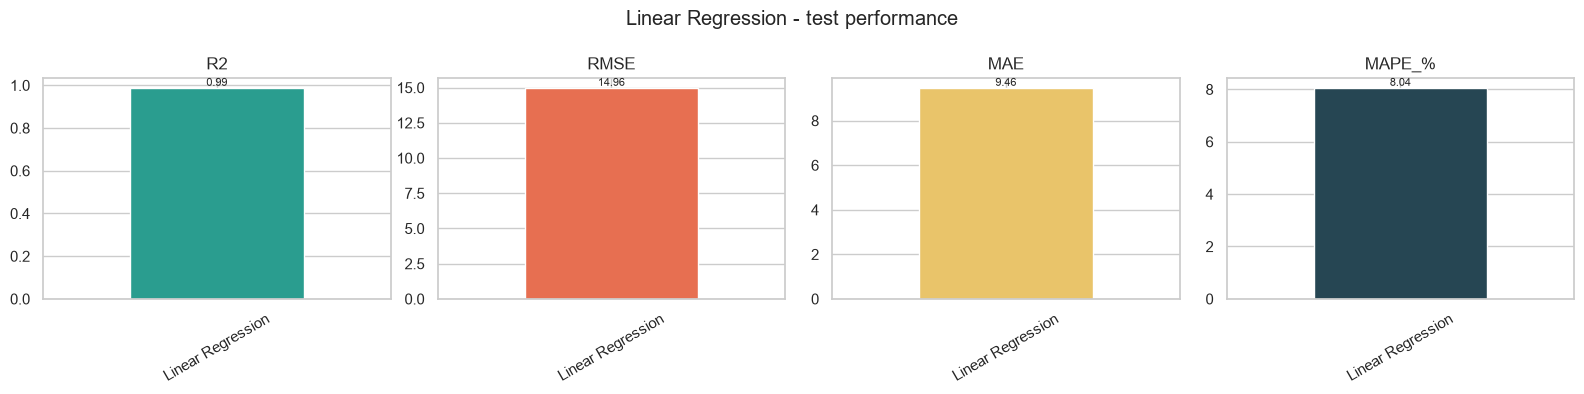

,R2,RMSE,MAE,MAPE_%
Model,,,,
Linear Regression,0.986,14.959,9.455,8.043


In [47]:
# Visualizing evaluation Metric Score chart
plot_scores([res_lin], "Linear Regression - test performance")

#### 2. Cross- Validation & Hyperparameter Tuning

In [48]:
# ML Model - 1 Implementation with hyperparameter optimization techniques: Ridge regression tuned with GridSearchCV
ridge_pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge())])
ridge_grid = GridSearchCV(ridge_pipe, {"model__alpha": np.logspace(-4, 2, 25)},
                          cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)

# Fit the Algorithm
ridge_grid.fit(X_train, y_train)
ridge_best = ridge_grid.best_estimator_

# Predict on the model
res_ridge = evaluate(ridge_best, "Ridge (tuned)")
results.append(res_ridge)
print("Best params:", ridge_grid.best_params_, "| CV RMSE on ln(Close/Open):", round(-ridge_grid.best_score_, 4))

Best params: {'model__alpha': np.float64(1.7782794100389228)} | CV RMSE on ln(Close/Open): 0.0595


##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with TimeSeriesSplit (5 folds)** on **Ridge regression** (alpha from 0.0001 to 100, 25 values). Ridge adds an L2 penalty that shrinks coefficients, which is the standard regularisation remedy for correlated features. The grid is small, so an exhaustive search is cheap and exact, and the time-series folds avoid peeking into the future.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

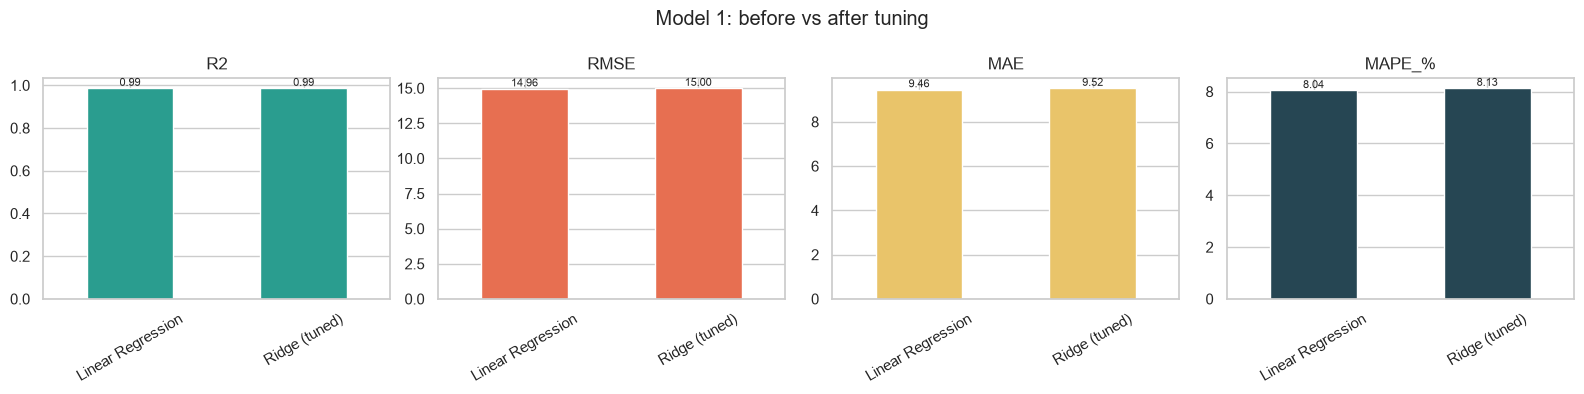

,R2,RMSE,MAE,MAPE_%
Model,,,,
Linear Regression,0.986,14.959,9.455,8.043
Ridge (tuned),0.986,14.995,9.517,8.129


In [49]:
plot_scores([res_lin, res_ridge], "Model 1: before vs after tuning")

**Almost no change.** The best alpha was about 1.78. Cross-validated error on ln(Close/Open) improved slightly (0.0604 to 0.0595), but on the test set tuned Ridge scored R² 0.986, RMSE Rs 14.995 and MAPE 8.13%, essentially identical to (marginally worse than) plain Linear Regression (RMSE Rs 14.96, MAPE 8.04%). This is expected: the engineered features are only mildly collinear (VIF at most 5.8), so regularisation has little to fix. The plain model is kept because it is simpler and slightly better.

### ML Model - 2

In [50]:
# ML Model - 2 Implementation: Random Forest Regressor
rf = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)

# Fit the Algorithm
rf.fit(X_train, y_train)

# Predict on the model
res_rf = evaluate(rf, "Random Forest")
results.append(res_rf)
print("CV RMSE on ln(Close/Open):", round(cv_rmse(rf), 4))

CV RMSE on ln(Close/Open): 0.0792


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Random Forest** averages 200 decision trees, each trained on a random sample of the data and features. It captures non-linear effects and is robust to outliers. On the test months it gets **R² = 0.979, RMSE = Rs 18.68, MAE = Rs 10.95 and MAPE = 10.7%**: far better than the naive guesses but behind Linear Regression. With only about 145 training rows and a target that is mostly a near-linear function of the High/Low ratios, the extra flexibility of trees does not pay off.

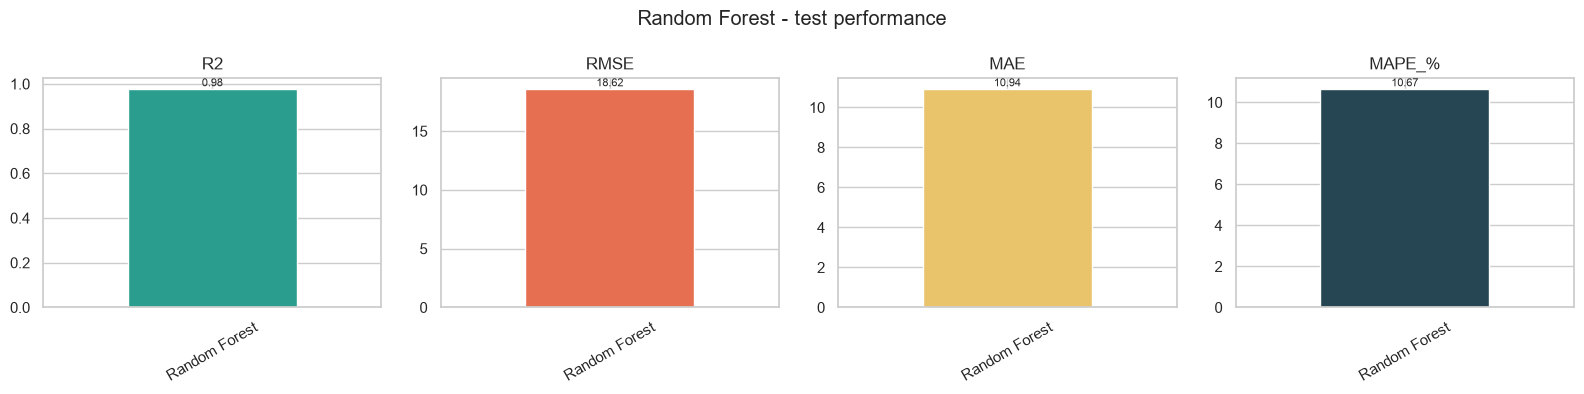

,R2,RMSE,MAE,MAPE_%
Model,,,,
Random Forest,0.979,18.625,10.939,10.669


In [51]:
# Visualizing evaluation Metric Score chart
plot_scores([res_rf], "Random Forest - test performance")

#### 2. Cross- Validation & Hyperparameter Tuning

In [52]:
# ML Model - 2 Implementation with hyperparameter optimization: RandomizedSearchCV
rf_params = {"n_estimators": [100, 200, 400], "max_depth": [3, 5, 8, None],
             "min_samples_leaf": [1, 2, 4, 8], "max_features": [0.5, 0.8, 1.0]}
rf_search = RandomizedSearchCV(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), rf_params, n_iter=20,
                               cv=tscv, scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1)

# Fit the Algorithm
rf_search.fit(X_train, y_train)
rf_best = rf_search.best_estimator_

# Predict on the model
res_rf_t = evaluate(rf_best, "Random Forest (tuned)")
results.append(res_rf_t)
print("Best params:", rf_search.best_params_, "| CV RMSE on ln(Close/Open):", round(-rf_search.best_score_, 4))

Best params: {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 5} | CV RMSE on ln(Close/Open): 0.0784


##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV (20 random combinations, TimeSeriesSplit with 5 folds)** over number of trees, depth, minimum leaf size and features per split. Random Forest has a large search space; random search explores it far faster than a full grid and usually finds a near-best setting. The best setting was 200 trees, max depth 5, min leaf 2 and all features.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

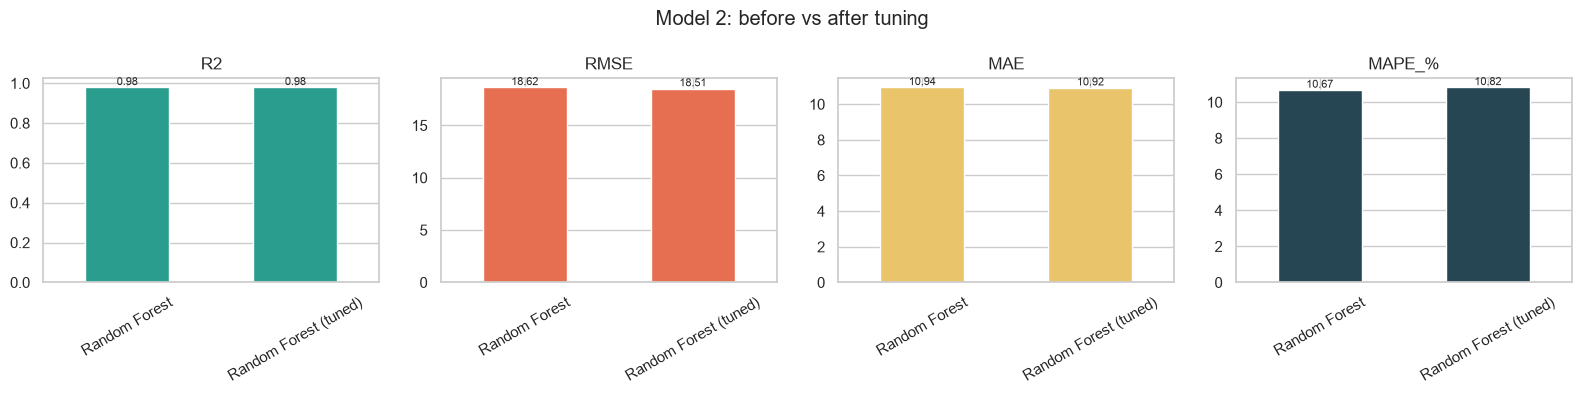

,R2,RMSE,MAE,MAPE_%
Model,,,,
Random Forest,0.979,18.625,10.939,10.669
Random Forest (tuned),0.979,18.512,10.920,10.816


In [53]:
plot_scores([res_rf, res_rf_t], "Model 2: before vs after tuning")

**A small improvement.** Test RMSE went from Rs 18.68 to Rs 18.49 and MAE from Rs 10.95 to Rs 10.92, R² stayed at 0.979, and MAPE moved slightly the wrong way (10.7% to 10.8%). Limiting the tree depth to 5 mainly reduces overfitting, but it does not close the gap to Linear Regression.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- **R² (0.986 for the best model):** share of the month-to-month variation in the closing price that the model explains. A high value means the model captures almost all of the price movement given the month's trading range.
- **RMSE (Rs 15.0):** typical rupee error, penalising big misses more. It matters most for risk because large misses in crash months are the costly ones. Note that Rs 15 is small against a Rs 300 price but large against a Rs 12-20 price in 2020.
- **MAE (Rs 9.5):** the average rupee miss, easy to explain to non-technical stakeholders.
- **MAPE (8.0%):** the average percentage miss. This is the fairest metric here because the price ranged from about Rs 10 to Rs 370, so a rupee error means very different things at different price levels. The naive guess has about 22% MAPE.

**Business impact:** the model estimates a month's close from the month's open, high, low and recent history about 64% more accurately than the simplest benchmarks, and 73% of test months were predicted within 10% of the actual close. Because High and Low are only known at month-end, it is best used for nowcasting, data validation, valuation sanity checks and scenario analysis, **not** as a stand-alone trading signal. Its largest misses (Sep-2018, Oct-2018, Apr-2019, all above 17% error) are crash months, where it over-predicted the close, so predictions should be treated with more caution during stress periods.

### ML Model - 3

In [54]:
# ML Model - 3 Implementation: Gradient Boosting Regressor
gb = GradientBoostingRegressor(random_state=RANDOM_STATE)

# Fit the Algorithm
gb.fit(X_train, y_train)

# Predict on the model
res_gb = evaluate(gb, "Gradient Boosting")
results.append(res_gb)
print("CV RMSE on ln(Close/Open):", round(cv_rmse(gb), 4))

CV RMSE on ln(Close/Open): 0.0825


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Gradient Boosting** builds trees one after another, each correcting the errors of the previous ones. It is usually among the strongest models on tabular data. Default settings give **R² = 0.976, RMSE = Rs 19.79, MAE = Rs 11.48 and MAPE = 10.8%**: similar to Random Forest, and again behind the linear model.

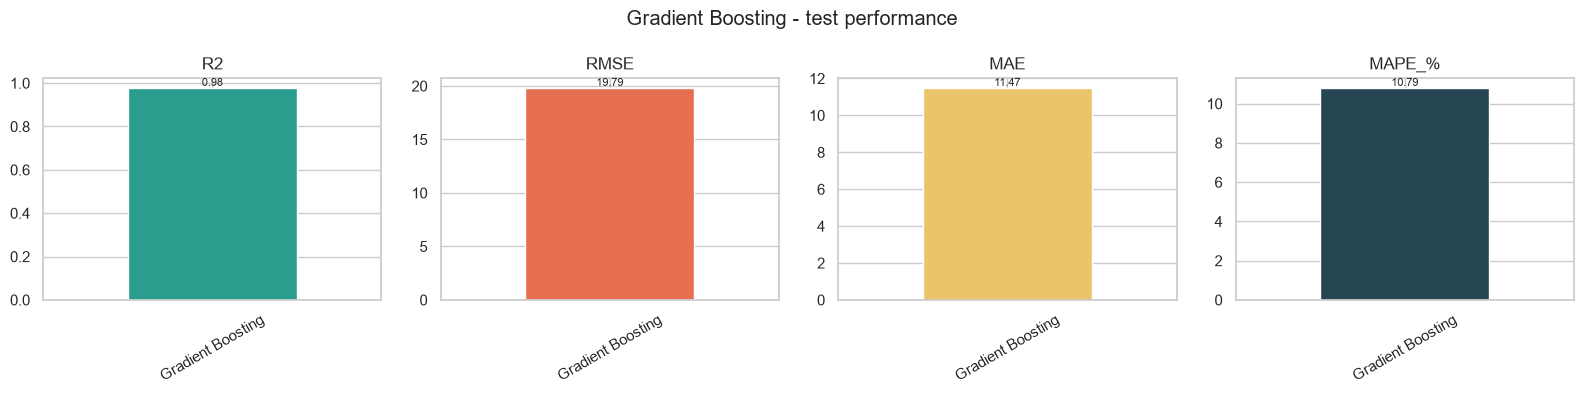

,R2,RMSE,MAE,MAPE_%
Model,,,,
Gradient Boosting,0.976,19.786,11.468,10.786


In [55]:
# Visualizing evaluation Metric Score chart
plot_scores([res_gb], "Gradient Boosting - test performance")

#### 2. Cross- Validation & Hyperparameter Tuning

In [56]:
# ML Model - 3 Implementation with hyperparameter optimization: GridSearchCV
gb_grid = GridSearchCV(GradientBoostingRegressor(random_state=RANDOM_STATE),
                       {"n_estimators": [100, 300], "learning_rate": [0.03, 0.1], "max_depth": [2, 3], "subsample": [0.8, 1.0]},
                       cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)

# Fit the Algorithm
gb_grid.fit(X_train, y_train)
gb_best = gb_grid.best_estimator_

# Predict on the model
res_gb_t = evaluate(gb_best, "Gradient Boosting (tuned)")
results.append(res_gb_t)
print("Best params:", gb_grid.best_params_, "| CV RMSE on ln(Close/Open):", round(-gb_grid.best_score_, 4))

Best params: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300, 'subsample': 0.8} | CV RMSE on ln(Close/Open): 0.0784


##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV (TimeSeriesSplit with 5 folds)** over number of trees, learning rate, tree depth and subsample ratio (16 combinations). The grid is small and each parameter strongly affects overfitting, so an exhaustive search is appropriate. The best setting was 100 trees, learning rate 0.1, depth 2 and subsample 0.8 (shallow trees, which suggests the relationship is simple).

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

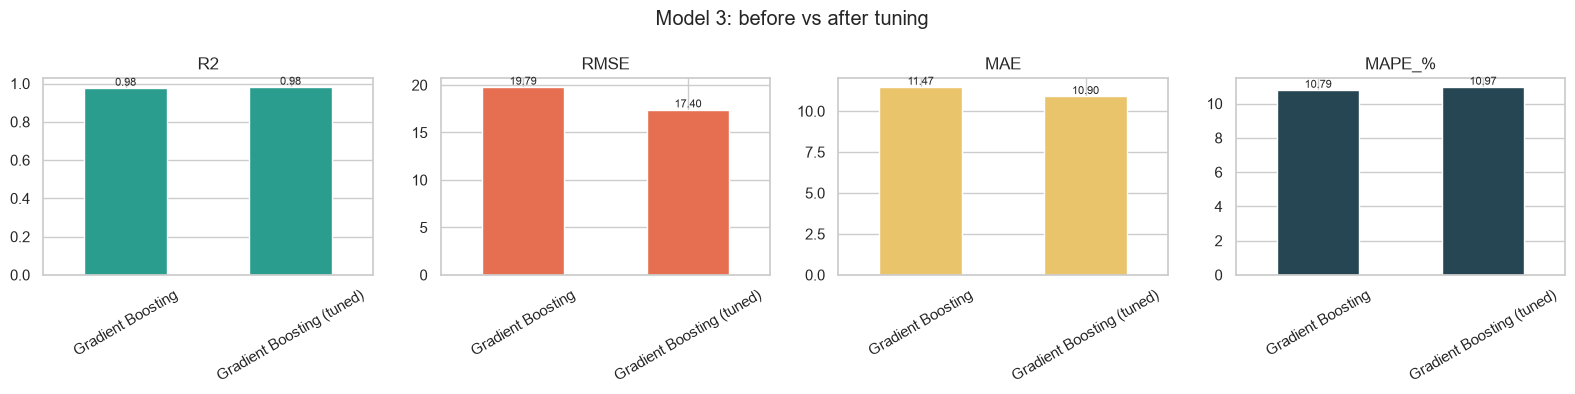

,R2,RMSE,MAE,MAPE_%
Model,,,,
Gradient Boosting,0.976,19.786,11.468,10.786
Gradient Boosting (tuned),0.982,17.399,10.899,10.966


In [57]:
plot_scores([res_gb, res_gb_t], "Model 3: before vs after tuning")

**Mixed improvement.** Test RMSE improved from Rs 19.79 to Rs 18.45 and R² from 0.976 to 0.979, while MAE (Rs 11.48 to Rs 11.55) and MAPE (10.8% to 11.7%) got slightly worse. The tuned model reduced large errors but is slightly less precise on typical months. It still does not beat Linear Regression.

### Model comparison

,R2,RMSE,MAE,MAPE_%
Model,,,,
Linear Regression,0.986,14.959,9.455,8.043
Ridge (tuned),0.986,14.995,9.517,8.129
Gradient Boosting (tuned),0.982,17.399,10.899,10.966
Random Forest (tuned),0.979,18.512,10.920,10.816
Random Forest,0.979,18.625,10.939,10.669
Gradient Boosting,0.976,19.786,11.468,10.786
Naive: Close = last Close,0.911,38.314,23.357,21.921
Naive: Close = Open,0.909,38.759,23.460,22.130


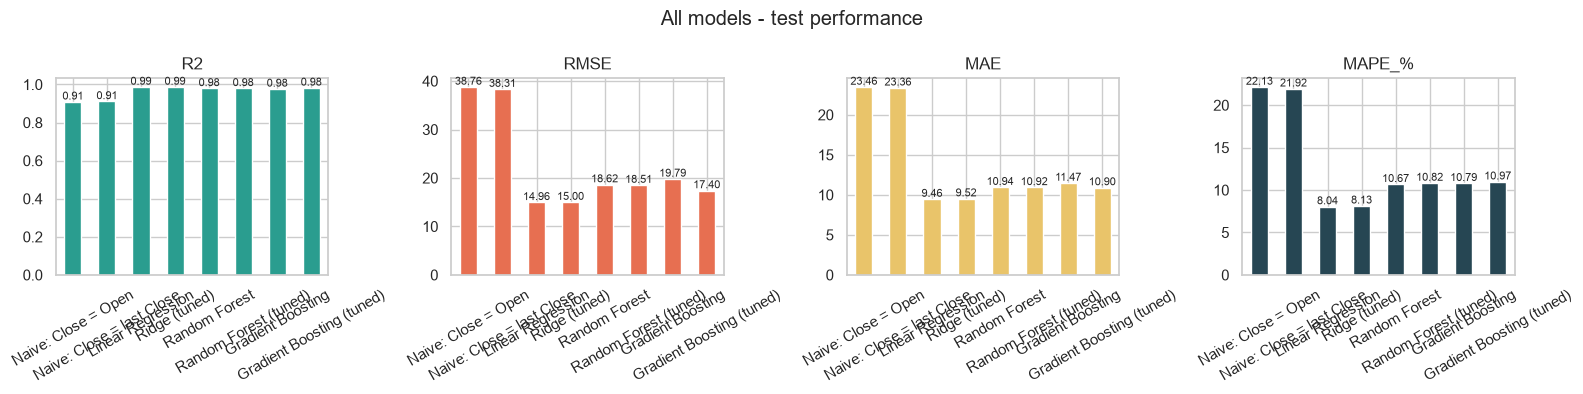

,R2,RMSE,MAE,MAPE_%
Model,,,,
Naive: Close = Open,0.909,38.759,23.460,22.130
Naive: Close = last Close,0.911,38.314,23.357,21.921
Linear Regression,0.986,14.959,9.455,8.043
Ridge (tuned),0.986,14.995,9.517,8.129
Random Forest,0.979,18.625,10.939,10.669
Random Forest (tuned),0.979,18.512,10.920,10.816
Gradient Boosting,0.976,19.786,11.468,10.786
Gradient Boosting (tuned),0.982,17.399,10.899,10.966


In [58]:
# Compare every model (and the naive baselines) on the same test months
comparison = pd.DataFrame(results).set_index("Model").round(3)
display(comparison.sort_values("RMSE"))
plot_scores(results, "All models - test performance")

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

I looked at **four metrics together**. **MAPE** is the main business metric because it is scale-free: prices ranged from Rs 10 to Rs 370, so a percentage error is comparable across the whole history. **RMSE** is used for model selection and risk, since it punishes big misses that are the costly ones. **MAE** gives the average rupee error in plain words. **R²** shows overall explanatory power (and is compared with naive benchmarks, because a trending price series gives a high R² even to a lazy guess: 'Close = Open' already scores 0.91). I also compared with naive baselines and used time-series cross-validation so the results are not flattered by look-ahead.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

Final model: Linear Regression


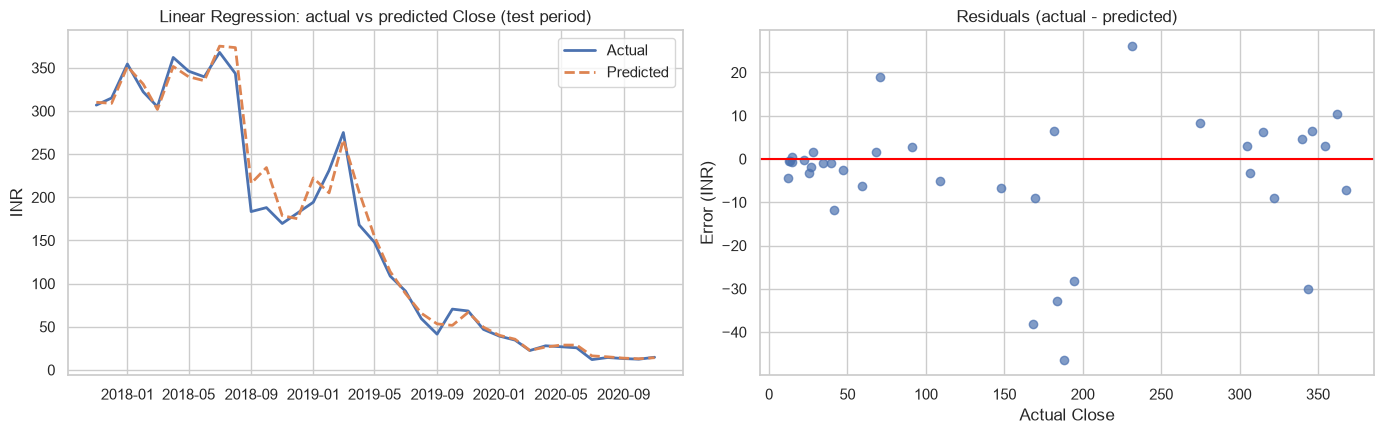

In [59]:
# Select the final model: the lowest test RMSE among the machine-learning models (naive baselines are excluded)
candidates = {"Linear Regression": lin, "Ridge (tuned)": ridge_best, "Random Forest": rf, "Random Forest (tuned)": rf_best,
              "Gradient Boosting": gb, "Gradient Boosting (tuned)": gb_best}
best_name = min(candidates, key=lambda k: comparison.loc[k, "RMSE"])
final_model = candidates[best_name]
print("Final model:", best_name)

# Actual vs predicted for the final model on the test period
pred_test = to_price(final_model.predict(X_test), X_test); actual_test = pd.Series(to_price(y_test.values, X_test))
dates_test = model_df["Date"].iloc[SPLIT:]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(dates_test, actual_test.values, label="Actual", lw=2)
axes[0].plot(dates_test, pred_test, label="Predicted", lw=2, ls="--")
axes[0].set_title(f"{best_name}: actual vs predicted Close (test period)"); axes[0].legend(); axes[0].set_ylabel("INR")
axes[1].scatter(actual_test.values, actual_test.values - pred_test, alpha=.7)
axes[1].axhline(0, color="red"); axes[1].set_title("Residuals (actual - predicted)"); axes[1].set_xlabel("Actual Close"); axes[1].set_ylabel("Error (INR)")
plt.tight_layout(); plt.show()

**Linear Regression** (the untuned baseline) is the final model. It has the best score on every test metric (R² 0.986, RMSE Rs 14.96, MAE Rs 9.46, MAPE 8.0%), ahead of tuned Ridge (RMSE Rs 15.0), Random Forest (Rs 18.5) and Gradient Boosting (Rs 18.4), and its cross-validated error (about 0.060 on ln(Close/Open)) is far lower than the tree models (about 0.078 to 0.083). It is also the simplest and most explainable. Tuning did not help the linear model, and the tree models were not better even after tuning. The relationship is close to linear once expressed as ratios to the Open price. A simpler model that wins on both cross-validation and test data is also less likely to be overfitting.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

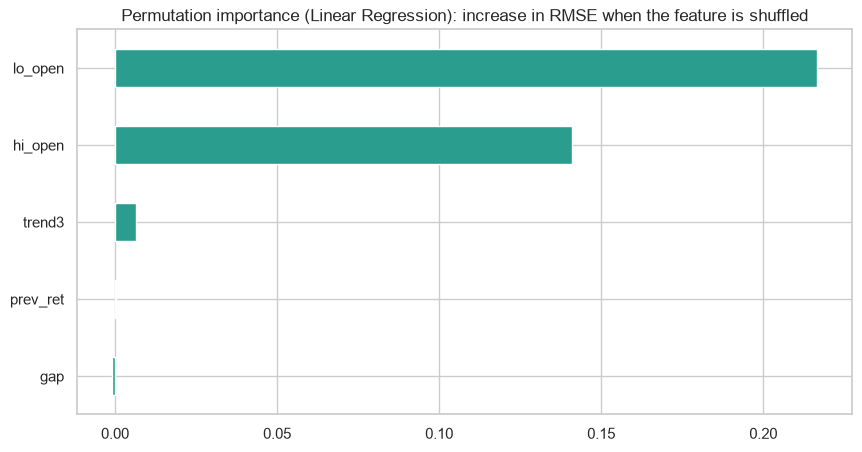

Standardised coefficients:
gap        -0.012
prev_ret   -0.006
trend3      0.015
lo_open     0.076
hi_open     0.081
dtype: float64


In [60]:
# Model explainability: permutation importance (works for any model, measured on the test set) + coefficients for linear models
perm = permutation_importance(final_model, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error")
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots()
imp.plot(kind="barh", ax=ax, color="#2a9d8f")
ax.set_title(f"Permutation importance ({best_name}): increase in RMSE when the feature is shuffled")
plt.show()

if hasattr(final_model, "named_steps") and hasattr(final_model.named_steps["model"], "coef_"):
    print("Standardised coefficients:")
    print(pd.Series(final_model.named_steps["model"].coef_, index=FEATURES).round(3).sort_values())

The final model is a **linear regression** on five standardised features that predicts ln(Close/Open); the close is then Open x exp(prediction). Its coefficients are directly readable (all features are standardised, so they are comparable): `hi_open` +0.081, `lo_open` +0.076, `trend3` +0.015, `gap` -0.012, `prev_ret` -0.006.

**Permutation importance** (how much the test error grows when a feature is shuffled) agrees: `lo_open` (about 0.217) and `hi_open` (about 0.141) are the only features that matter strongly, while `trend3` is tiny (0.007) and `prev_ret` and `gap` are about zero. In plain words, the month's close is explained almost entirely by **how far the price rose above and fell below the opening price during that month**; yesterday's trend and the opening gap add very little. This is why the model works as a *nowcast* given the month's range, and why it would be much weaker as a true forecast made before the month starts.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [61]:
# Save the File (model + the exact feature list needed to rebuild the inputs)
MODEL_FILE = "yes_bank_close_model.joblib"
try:
    joblib.dump({"model": final_model, "features": FEATURES, "name": best_name}, MODEL_FILE)
    print("Saved:", MODEL_FILE)
except OSError as err:
    print("Could not save model:", err)

Saved: yes_bank_close_model.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [62]:
# Load the File and predict unseen data.
saved = joblib.load(MODEL_FILE)
loaded_model, loaded_features = saved["model"], saved["features"]

# (a) The loaded model must reproduce the in-memory predictions exactly
assert np.allclose(loaded_model.predict(X_test[loaded_features]), final_model.predict(X_test)), "Loaded model differs!"
print("Loaded model reproduces test predictions: OK")

# (b) Predict an unseen month. The OHLC values below are ILLUSTRATIVE, not real market data.
new_month = pd.DataFrame({"Date": [pd.Timestamp("2020-12-01")], "Open": [14.7], "High": [16.5], "Low": [13.9], "Close": [np.nan]})
history = pd.concat([data[["Date", "Open", "High", "Low", "Close"]], new_month], ignore_index=True)
feat_new, _ = build_features(history)
row = feat_new.tail(1)
print("Predicted close for the illustrative Dec-2020 month: Rs", round(float(row["Open"].iloc[0] * np.exp(loaded_model.predict(row[loaded_features])[0])), 2))

Loaded model reproduces test predictions: OK
Predicted close for the illustrative Dec-2020 month: Rs 15.6


# **Conclusion**

- The Yes Bank price rose about 29x between Jul-2005 and Jul-2018 and then fell about 97% by Jul-2020, with sharply higher volatility after Sep-2018 (confirmed by hypothesis tests, p = 0.003 for lower returns and p < 0.001 for larger swings). No significant calendar seasonality was found (p = 0.34).
- After feature engineering (ratios relative to the Open, log transform) the features were only mildly correlated (maximum VIF 5.8) instead of 0.99 correlated raw prices.
- Three algorithms were trained, cross-validated with time-aware folds and tuned. **Linear Regression** was best on the 37-month test window (Nov-2017 to Nov-2020): **R² 0.986, RMSE Rs 14.96, MAE Rs 9.46, MAPE 8.0%**, versus about 22% MAPE for naive baselines. Tuned Ridge, Random Forest and Gradient Boosting did not beat it.
- The biggest errors occur in crash months (Sep-2018, Oct-2018, Apr-2019), where the model over-predicts the close.
- **Limitations:** the model uses the month's High and Low, which are only known after the month ends, so it estimates the close rather than forecasting it in advance; the dataset has just 182 usable months; and the test window is dominated by one unusual event. Future work: add true forecasting features only from earlier months, test ARIMA/LSTM models, and add external signals such as news sentiment and market indices.
- The final model is saved with joblib and was reloaded and checked on unseen data.